
# Proyecto Final: Modelamiento predictivo y simulación de reglas de detección de fraude

## 1. Introducción

El presente proyecto constituye una continuación del trabajo desarrollado durante el Midterm, denominado "Análisis de patrones transaccionales para el diseño y evaluación de reglas de detección de fraude en pagos electrónicos".

En la primera fase se realizó la exploración de datos transaccionales, identificando patrones relacionados con el monto, horario y categoría comercial. A partir de estos hallazgos, se diseñaron y evaluaron tres reglas exploratorias para la detección de fraude.

En esta segunda fase se propone incorporar técnicas de aprendizaje automático (Machine Learning) para desarrollar modelos predictivos capaces de estimar el riesgo de fraude en transacciones electrónicas.

Adicionalmente, se comparará el desempeño de los modelos predictivos frente a las reglas diseñadas previamente y se simulará su comportamiento operativo, considerando la detección de fraudes y la generación de falsas alertas.

## 1.1. Objetivo general

Desarrollar y evaluar modelos predictivos de detección de fraude mediante técnicas de Machine Learning, comparando su desempeño con reglas tradicionales y simulando su aplicación sobre transacciones electrónicas.

## 1.2. Objetivos específicos

1. Preparar los datos transaccionales para el entrenamiento de modelos predictivos.
2. Implementar algoritmos de clasificación supervisada.
3. Evaluar el desempeño mediante precisión, recall, F1-Score, matrices de confusión y otras métricas apropiadas para datos desbalanceados.
4. Comparar los modelos predictivos con las tres reglas diseñadas durante el Midterm.
5. Simular escenarios operativos para analizar el impacto de las alertas generadas.

## 1.3. Herramientas

- Python
- Jupyter Notebook
- Pandas y NumPy
- Scikit-learn
- Matplotlib y Seaborn

## 1.4. Fuente de datos

Credit Card Transactions Fraud Detection Dataset, disponible en Kaggle.

Archivos originales:
- fraudTrain.csv
- fraudTest.csv

Variable objetivo: is_fraud

## 1.5. Continuidad con el Midterm

Repositorio original:
https://github.com/wilydus-png/Proyecto-Fraude-Midterm


In [1]:

# Verificación del entorno de trabajo

import sys
import os
import importlib.metadata as metadata

print("Python:", sys.version.split()[0])
print("Carpeta de trabajo:", os.getcwd())

librerias = [
    "pandas",
    "numpy",
    "scikit-learn",
    "matplotlib",
    "seaborn"
]

for libreria in librerias:
    try:
        print(f"{libreria}: {metadata.version(libreria)}")
    except metadata.PackageNotFoundError:
        print(f"{libreria}: NO INSTALADA")


Python: 3.13.9
Carpeta de trabajo: C:\Users\eduar\Downloads\Proyecto Midterm
pandas: 2.3.3
numpy: 2.3.5
scikit-learn: 1.7.2
matplotlib: 3.10.6
seaborn: 0.13.2



## 2. Carga y verificación de datos

En esta etapa se cargarán los conjuntos de datos históricos correspondientes a las transacciones electrónicas.

Se utilizarán los archivos `fraudTrain.csv` y `fraudTest.csv`, que contienen información sobre transacciones legítimas y fraudulentas.

El propósito es verificar la estructura de los datos, identificar sus dimensiones y comprobar la presencia de la variable objetivo `is_fraud`, que posteriormente permitirá desarrollar modelos de clasificación supervisada.

Se conservará inicialmente la separación original entre entrenamiento y prueba para evitar que el modelo aprenda de los datos destinados a evaluar su desempeño.


In [2]:

# PASO 2: Carga de los datos originales

import pandas as pd
from pathlib import Path

# Ubicación de los archivos
carpeta = Path.cwd()

archivo_train = carpeta / "fraudTrain.csv"
archivo_test = carpeta / "fraudTest.csv"

# Comprobar que ambos archivos existan
print("Archivo Train encontrado:", archivo_train.exists())
print("Archivo Test encontrado:", archivo_test.exists())

# Cargar los archivos
if archivo_train.exists() and archivo_test.exists():

    df_train = pd.read_csv(archivo_train)
    df_test = pd.read_csv(archivo_test)

    print("\nDATOS CARGADOS CORRECTAMENTE")

    print("\nDimensiones entrenamiento:", df_train.shape)
    print("Dimensiones prueba:", df_test.shape)

    print("\nVariable objetivo disponible:")
    print("Train:", "is_fraud" in df_train.columns)
    print("Test:", "is_fraud" in df_test.columns)

    display(df_train.head())

else:
    print("\nNo se encontraron ambos archivos CSV.")
    print("Revisar la ubicación antes de continuar.")


Archivo Train encontrado: True
Archivo Test encontrado: True

DATOS CARGADOS CORRECTAMENTE

Dimensiones entrenamiento: (1296675, 23)
Dimensiones prueba: (555719, 23)

Variable objetivo disponible:
Train: True
Test: True


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0



## 3. Análisis de la variable objetivo

La variable `is_fraud` permite identificar si una transacción es legítima o fraudulenta:

- **0:** Transacción legítima.
- **1:** Transacción fraudulenta.

En esta etapa se analizará la distribución de ambas clases en los conjuntos de entrenamiento y prueba.

Este análisis es fundamental para identificar posibles desequilibrios en los datos, debido a que los casos de fraude suelen representar una proporción reducida del total de transacciones.

Los resultados permitirán seleccionar técnicas y métricas adecuadas para el posterior entrenamiento y evaluación de los modelos predictivos.


In [3]:

# PASO 3: Distribución de la variable objetivo

# Comprobar la existencia de is_fraud
if "is_fraud" in df_train.columns and "is_fraud" in df_test.columns:

    # Calcular frecuencias y porcentajes
    resumen = pd.DataFrame({
        "Entrenamiento": df_train["is_fraud"].value_counts(),
        "Prueba": df_test["is_fraud"].value_counts()
    }).fillna(0).astype(int)

    # Identificar las clases
    resumen.index = resumen.index.map({
        0: "Legítimas",
        1: "Fraudulentas"
    })

    # Agregar totales
    resumen.loc["Total"] = resumen.sum()

    # Calcular porcentajes
    resumen["% Entrenamiento"] = (
        resumen["Entrenamiento"] /
        resumen.loc["Total", "Entrenamiento"] * 100
    ).round(3)

    resumen["% Prueba"] = (
        resumen["Prueba"] /
        resumen.loc["Total", "Prueba"] * 100
    ).round(3)

    print("DISTRIBUCIÓN DE TRANSACCIONES")
    display(resumen)

else:
    print("ERROR: No se encontró la variable is_fraud.")


DISTRIBUCIÓN DE TRANSACCIONES


,Entrenamiento,Prueba,% Entrenamiento,% Prueba
is_fraud,,,,
Legítimas,1289169,553574,99.421,99.614
Fraudulentas,7506,2145,0.579,0.386
Total,1296675,555719,100.000,100.000



## 4. Visualización del desbalance de clases

Con el propósito de comprender la distribución de la variable objetivo `is_fraud`, se realiza una comparación gráfica entre las transacciones legítimas y fraudulentas de los conjuntos de entrenamiento y prueba.

Debido a la baja proporción de fraudes, se utilizan dos gráficos complementarios:

1. Distribución porcentual de las transacciones legítimas y fraudulentas.
2. Comparación específica de los porcentajes de fraude entre entrenamiento y prueba.

Esta visualización permite evidenciar el desbalance de clases y justificar el uso posterior de métricas especializadas para evaluar los modelos predictivos.


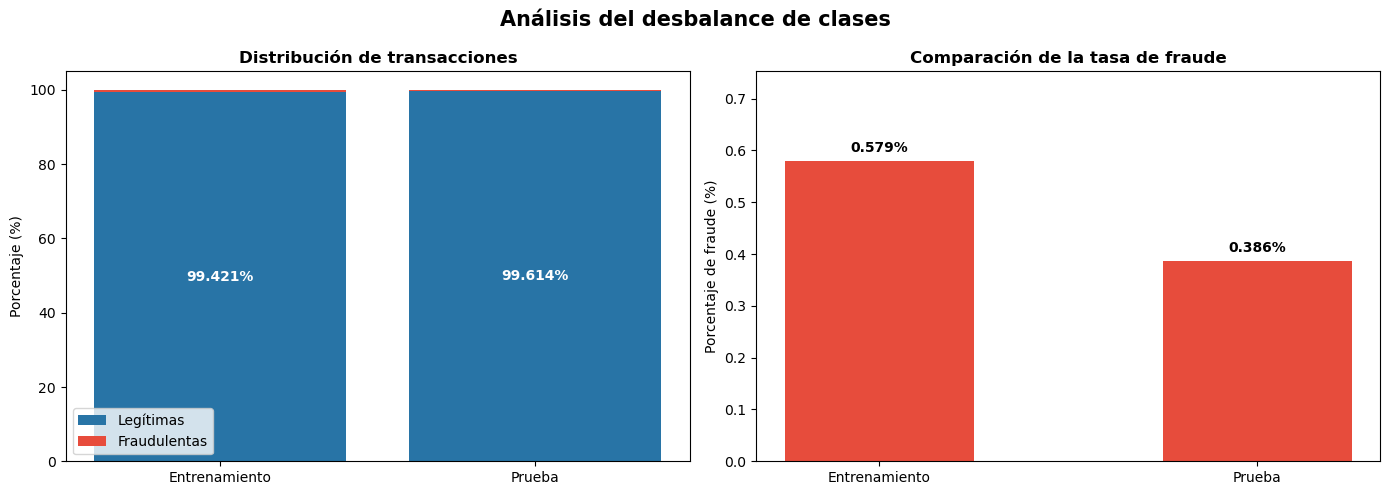

Gráfico guardado correctamente.


In [44]:

# PASO 4: Visualización del desbalance de clases

import matplotlib.pyplot as plt
import numpy as np

# Calcular porcentajes
porcentajes = pd.DataFrame({
    "Entrenamiento": (
        df_train["is_fraud"].value_counts(normalize=True) * 100
    ),
    "Prueba": (
        df_test["is_fraud"].value_counts(normalize=True) * 100
    )
}).fillna(0)

legitimas = porcentajes.loc[0].values
fraudes = porcentajes.loc[1].values

grupos = ["Entrenamiento", "Prueba"]
x = np.arange(len(grupos))

# Crear figura con dos gráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribución general
axes[0].bar(
    x, legitimas,
    label="Legítimas", color="#2874A6"
)

axes[0].bar(
    x, fraudes,
    bottom=legitimas,
    label="Fraudulentas", color="#E74C3C"
)

axes[0].set_title(
    "Distribución de transacciones",
    fontweight="bold"
)
axes[0].set_ylabel("Porcentaje (%)")
axes[0].set_xticks(x, grupos)
axes[0].set_ylim(0, 105)
axes[0].legend()

for i, valor in enumerate(legitimas):
    axes[0].text(
        i, valor / 2,
        f"{valor:.3f}%",
        ha="center", va="center",
        color="white", fontweight="bold"
    )

# Gráfico 2: Porcentaje específico de fraude
barras = axes[1].bar(
    grupos, fraudes,
    color="#E74C3C", width=0.5
)

axes[1].set_title(
    "Comparación de la tasa de fraude",
    fontweight="bold"
)
axes[1].set_ylabel("Porcentaje de fraude (%)")
axes[1].set_ylim(0, max(fraudes) * 1.3)

for barra, valor in zip(barras, fraudes):
    axes[1].text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + max(fraudes) * 0.03,
        f"{valor:.3f}%",
        ha="center",
        fontweight="bold"
    )

plt.suptitle(
    "Análisis del desbalance de clases",
    fontsize=15,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "01_desbalance_clases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")




## 5. Identificación y selección de variables predictivas

En esta etapa se analizará la estructura de los conjuntos de datos para identificar las variables que pueden utilizarse durante el entrenamiento de los modelos predictivos.

Las variables predictivas representan las características de cada transacción que el algoritmo analizará para reconocer patrones asociados al fraude.

Se distinguirán tres tipos de variables:

1. **Variables predictivas:** características transaccionales que podrían contribuir a identificar operaciones fraudulentas.
2. **Variable objetivo:** `is_fraud`, que indica si la transacción fue legítima (0) o fraudulenta (1).
3. **Variables que requieren evaluación o exclusión:** identificadores, campos redundantes o información que no estaría disponible al momento de realizar la predicción.

La selección definitiva de variables se realizará considerando su disponibilidad operativa, calidad, pertinencia y riesgo de fuga de información.


In [7]:

# PASO 5: Identificación de variables disponibles

# Crear una tabla con las características de cada columna
resumen_variables = pd.DataFrame({
    "Variable": df_train.columns,
    "Tipo de dato": df_train.dtypes.astype(str).values,
    "Valores nulos": df_train.isnull().sum().values,
    "% Nulos": (
        df_train.isnull().mean().values * 100
    ).round(2),
    "Valores únicos": df_train.nunique().values
})

print("RESUMEN DE VARIABLES DISPONIBLES")

display(resumen_variables)

print("\nTOTAL DE VARIABLES:", len(df_train.columns))


RESUMEN DE VARIABLES DISPONIBLES


,Variable,Tipo de dato,Valores nulos,% Nulos,Valores únicos
0,Unnamed: 0,int64,0,0.0,1296675
1,trans_date_trans_time,object,0,0.0,1274791
2,cc_num,int64,0,0.0,983
3,merchant,object,0,0.0,693
4,category,object,0,0.0,14
5,amt,float64,0,0.0,52928
6,first,object,0,0.0,352
7,last,object,0,0.0,481
8,gender,object,0,0.0,2
9,street,object,0,0.0,983



TOTAL DE VARIABLES: 23



## 6. Preparación de variables predictivas

### 6.1. Transformación de variables temporales

La fecha y hora de una transacción pueden aportar información relevante para identificar patrones asociados al fraude.

En esta etapa se transformará la variable `trans_date_trans_time` para obtener:

- Hora de la transacción.
- Día de la semana.
- Indicador de fin de semana.

Estas nuevas características permitirán que los modelos predictivos analicen patrones temporales y aprendan posibles relaciones con la ocurrencia de fraude.

Las transformaciones se aplicarán tanto al conjunto de entrenamiento como al de prueba, conservando los datos originales.


In [8]:

# PASO 6.1: Transformación de variables temporales

# Crear copias para conservar los datos originales
train_modelo = df_train.copy()
test_modelo = df_test.copy()

# Aplicar las mismas transformaciones a ambos conjuntos
for df in [train_modelo, test_modelo]:

    # Convertir fecha y hora a formato datetime
    df["trans_date_trans_time"] = pd.to_datetime(
        df["trans_date_trans_time"],
        errors="coerce"
    )

    # Extraer hora de la transacción
    df["hora"] = df["trans_date_trans_time"].dt.hour

    # Extraer día de la semana (lunes=0, domingo=6)
    df["dia_semana"] = (
        df["trans_date_trans_time"].dt.dayofweek
    )

    # Identificar fines de semana
    df["fin_semana"] = (
        df["dia_semana"] >= 5
    ).astype(int)

# Verificar resultados
print("VARIABLES TEMPORALES GENERADAS")

columnas = [
    "trans_date_trans_time",
    "hora",
    "dia_semana",
    "fin_semana",
    "is_fraud"
]

display(train_modelo[columnas].head(10))

print("\nFechas inválidas:")
print(
    "Entrenamiento:",
    train_modelo["trans_date_trans_time"].isna().sum()
)
print(
    "Prueba:",
    test_modelo["trans_date_trans_time"].isna().sum()
)


VARIABLES TEMPORALES GENERADAS


,trans_date_trans_time,hora,dia_semana,fin_semana,is_fraud
0,2019-01-01 00:00:18,0,1,0,0
1,2019-01-01 00:00:44,0,1,0,0
2,2019-01-01 00:00:51,0,1,0,0
3,2019-01-01 00:01:16,0,1,0,0
4,2019-01-01 00:03:06,0,1,0,0
5,2019-01-01 00:04:08,0,1,0,0
6,2019-01-01 00:04:42,0,1,0,0
7,2019-01-01 00:05:08,0,1,0,0
8,2019-01-01 00:05:18,0,1,0,0
9,2019-01-01 00:06:01,0,1,0,0



Fechas inválidas:
Entrenamiento: 0
Prueba: 0



### 6.2. Cálculo de la distancia geográfica

La información geográfica constituye una característica potencialmente útil para el análisis de transacciones fraudulentas.

En esta etapa se calculará la distancia aproximada entre las coordenadas asociadas al cliente (`lat`, `long`) y las coordenadas del comercio (`merch_lat`, `merch_long`).

Para ello se utilizará la fórmula de Haversine, que permite determinar la distancia sobre la superficie terrestre entre dos puntos geográficos.

La nueva variable `distancia_km` se incorporará a los conjuntos de entrenamiento y prueba para su posterior utilización en los modelos predictivos.

Esta distancia no representa necesariamente el desplazamiento real del titular de la tarjeta ni constituye, por sí sola, evidencia de fraude.


In [9]:

# PASO 6.2: Cálculo de distancia geográfica

import numpy as np

# Función para calcular distancia mediante Haversine
def calcular_distancia(lat1, lon1, lat2, lon2):

    # Radio aproximado de la Tierra en kilómetros
    R = 6371

    # Convertir grados a radianes
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    # Diferencias entre coordenadas
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Fórmula de Haversine
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

# Aplicar a entrenamiento y prueba
for df in [train_modelo, test_modelo]:

    df["distancia_km"] = calcular_distancia(
        df["lat"],
        df["long"],
        df["merch_lat"],
        df["merch_long"]
    )

# Mostrar resultados
print("VARIABLE GEOGRÁFICA GENERADA")

columnas = [
    "lat",
    "long",
    "merch_lat",
    "merch_long",
    "distancia_km",
    "is_fraud"
]

display(
    train_modelo[columnas].head(10).round(2)
)

# Resumen estadístico
print("\nRESUMEN DE DISTANCIAS - ENTRENAMIENTO")

display(
    train_modelo["distancia_km"]
    .describe()
    .round(2)
)

# Comprobar valores no válidos
print("\nVALORES INVÁLIDOS")

print(
    "Entrenamiento:",
    train_modelo["distancia_km"].isna().sum()
)

print(
    "Prueba:",
    test_modelo["distancia_km"].isna().sum()
)


VARIABLE GEOGRÁFICA GENERADA


,lat,long,merch_lat,merch_long,distancia_km,is_fraud
0,36.08,-81.18,36.01,-82.05,78.60,0
1,48.89,-118.21,49.16,-118.19,30.21,0
2,42.18,-112.26,43.15,-112.15,108.21,0
3,46.23,-112.11,47.03,-112.56,95.67,0
4,38.42,-79.46,38.67,-78.63,77.56,0
5,40.38,-75.20,40.65,-76.15,85.92,0
6,37.99,-100.99,37.16,-100.15,118.12,0
7,38.84,-78.60,38.95,-78.54,12.77,0
8,40.34,-79.66,40.35,-79.96,25.27,0
9,36.52,-87.35,37.18,-87.49,74.08,0



RESUMEN DE DISTANCIAS - ENTRENAMIENTO


count    1296675.00
mean          76.11
std           29.12
min            0.02
25%           55.33
50%           78.23
75%           98.50
max          152.12
Name: distancia_km, dtype: float64


VALORES INVÁLIDOS
Entrenamiento: 0
Prueba: 0



### 6.3. Selección de variables predictivas

En esta etapa se seleccionan las características transaccionales que serán utilizadas para desarrollar los modelos predictivos de fraude.

Se consideran variables relacionadas con el monto de la operación, el comercio, la categoría comercial, el comportamiento temporal y las características geográficas.

Las variables categóricas, como `category` y `merchant`, serán transformadas posteriormente mediante técnicas de codificación, mientras que las variables numéricas serán utilizadas según los requerimientos de cada algoritmo.

La variable `is_fraud` se mantendrá separada de las características predictivas, debido a que representa el resultado que el modelo deberá aprender a predecir.


In [10]:

# PASO 6.3: Selección de variables predictivas

# Variables numéricas
variables_numericas = [
    "amt",
    "hora",
    "dia_semana",
    "fin_semana",
    "distancia_km",
    "city_pop"
]

# Variables categóricas
variables_categoricas = [
    "category",
    "merchant"
]

# Unir las variables seleccionadas
variables_modelo = (
    variables_numericas + variables_categoricas
)

# Crear matrices de características
X_train = train_modelo[variables_modelo].copy()
X_test = test_modelo[variables_modelo].copy()

# Crear variables objetivo
y_train = train_modelo["is_fraud"].copy()
y_test = test_modelo["is_fraud"].copy()

# Mostrar resultados
print("VARIABLES SELECCIONADAS PARA MODELAMIENTO")

print("\nVariables numéricas:")
print(variables_numericas)

print("\nVariables categóricas:")
print(variables_categoricas)

print("\nDimensiones de los conjuntos:")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nPRIMERAS CINCO TRANSACCIONES")

display(X_train.head())

print("\nVALORES NULOS EN VARIABLES SELECCIONADAS")

print("Entrenamiento:", X_train.isna().sum().sum())
print("Prueba:", X_test.isna().sum().sum())


VARIABLES SELECCIONADAS PARA MODELAMIENTO

Variables numéricas:
['amt', 'hora', 'dia_semana', 'fin_semana', 'distancia_km', 'city_pop']

Variables categóricas:
['category', 'merchant']

Dimensiones de los conjuntos:
X_train: (1296675, 8)
X_test: (555719, 8)
y_train: (1296675,)
y_test: (555719,)

PRIMERAS CINCO TRANSACCIONES


,amt,hora,dia_semana,fin_semana,distancia_km,city_pop,category,merchant
0,4.97,0,1,0,78.597568,3495,misc_net,"fraud_Rippin, Kub and Mann"
1,107.23,0,1,0,30.212176,149,grocery_pos,"fraud_Heller, Gutmann and Zieme"
2,220.11,0,1,0,108.206083,4154,entertainment,fraud_Lind-Buckridge
3,45.00,0,1,0,95.673231,1939,gas_transport,"fraud_Kutch, Hermiston and Farrell"
4,41.96,0,1,0,77.556744,99,misc_pos,fraud_Keeling-Crist



VALORES NULOS EN VARIABLES SELECCIONADAS
Entrenamiento: 0
Prueba: 0



## 7. División de datos para entrenamiento y validación

Para desarrollar modelos predictivos confiables, se requiere separar los datos en tres conjuntos: entrenamiento, validación y prueba.

El conjunto original de entrenamiento se dividirá cronológicamente en dos partes:

- **80 %:** entrenamiento del modelo.
- **20 %:** validación del modelo.

El conjunto original de prueba se mantendrá independiente y se utilizará únicamente para la evaluación final.

Se empleará una división temporal para evitar que el modelo sea entrenado con información posterior a las transacciones que se pretende predecir.

Adicionalmente, se analizará la distribución de las transacciones fraudulentas en cada conjunto para comprobar que exista una cantidad suficiente de casos positivos.


In [11]:

# PASO 7: División cronológica de entrenamiento y validación

# Ordenar las transacciones originales por fecha
indices_ordenados = (
    train_modelo
    .sort_values("trans_date_trans_time")
    .index
)

# Organizar características y etiquetas
X_ordenado = X_train.loc[indices_ordenados]
y_ordenado = y_train.loc[indices_ordenados]

# Calcular punto de división (80 %)
punto_division = int(len(X_ordenado) * 0.80)

# Crear conjuntos de entrenamiento y validación
X_entrenamiento = X_ordenado.iloc[:punto_division].copy()
X_validacion = X_ordenado.iloc[punto_division:].copy()

y_entrenamiento = y_ordenado.iloc[:punto_division].copy()
y_validacion = y_ordenado.iloc[punto_division:].copy()

# Mostrar dimensiones
print("DIVISIÓN CRONOLÓGICA DE DATOS")

print("\nEntrenamiento:", X_entrenamiento.shape)
print("Validación:", X_validacion.shape)
print("Prueba:", X_test.shape)

# Crear resumen de fraude
resumen_division = pd.DataFrame({
    "Conjunto": [
        "Entrenamiento",
        "Validación",
        "Prueba"
    ],
    "Transacciones": [
        len(y_entrenamiento),
        len(y_validacion),
        len(y_test)
    ],
    "Fraudes": [
        int(y_entrenamiento.sum()),
        int(y_validacion.sum()),
        int(y_test.sum())
    ]
})

resumen_division["% Fraude"] = (
    resumen_division["Fraudes"] /
    resumen_division["Transacciones"] * 100
).round(3)

print("\nDISTRIBUCIÓN DE FRAUDES")

display(resumen_division)

# Verificar los periodos temporales
fechas_ordenadas = (
    train_modelo.loc[
        indices_ordenados, "trans_date_trans_time"
    ]
)

print("\nPERIODOS DE ENTRENAMIENTO Y VALIDACIÓN")

print(
    "Entrenamiento:",
    fechas_ordenadas.iloc[0],
    "hasta",
    fechas_ordenadas.iloc[punto_division - 1]
)

print(
    "Validación:",
    fechas_ordenadas.iloc[punto_division],
    "hasta",
    fechas_ordenadas.iloc[-1]
)

print(
    "Prueba:",
    test_modelo["trans_date_trans_time"].min(),
    "hasta",
    test_modelo["trans_date_trans_time"].max()
)


DIVISIÓN CRONOLÓGICA DE DATOS

Entrenamiento: (1037340, 8)
Validación: (259335, 8)
Prueba: (555719, 8)

DISTRIBUCIÓN DE FRAUDES


,Conjunto,Transacciones,Fraudes,% Fraude
0,Entrenamiento,1037340,5968,0.575
1,Validación,259335,1538,0.593
2,Prueba,555719,2145,0.386



PERIODOS DE ENTRENAMIENTO Y VALIDACIÓN
Entrenamiento: 2019-01-01 00:00:18 hasta 2020-03-06 07:15:17
Validación: 2020-03-06 07:16:43 hasta 2020-06-21 12:13:37
Prueba: 2020-06-21 12:14:25 hasta 2020-12-31 23:59:34



## 8. Preparación de datos para Machine Learning

### 8.1. Codificación y estandarización de variables

Para entrenar los modelos predictivos es necesario transformar las características seleccionadas a una representación numérica adecuada.

Se aplicarán dos procedimientos:

1. **Estandarización:** mediante StandardScaler se ajustarán las variables numéricas para que tengan una escala comparable.
2. **Codificación categórica:** mediante OneHotEncoder se convertirán las variables `category` y `merchant` en indicadores numéricos.

Se utilizará ColumnTransformer para integrar ambas transformaciones.

Los parámetros de transformación se aprenderán únicamente del conjunto de entrenamiento y posteriormente se aplicarán a los conjuntos de validación y prueba, evitando fugas de información.

En esta etapa se verificará la configuración del preprocesamiento antes de entrenar el primer modelo predictivo.


In [12]:

# PASO 8: Configuración del preprocesamiento

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Configurar transformaciones
preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        ),
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            variables_categoricas
        )
    ],
    sparse_threshold=1.0
)

print("PREPROCESAMIENTO CONFIGURADO")

print("\nVariables numéricas:")
print(variables_numericas)

print("\nVariables categóricas:")
print(variables_categoricas)

print("\nTransformaciones:")
print("- StandardScaler para variables numéricas")
print("- OneHotEncoder para variables categóricas")

print("\nConjuntos disponibles:")
print("Entrenamiento:", X_entrenamiento.shape)
print("Validación:", X_validacion.shape)
print("Prueba:", X_test.shape)

print("\nConfiguración completada correctamente.")


PREPROCESAMIENTO CONFIGURADO

Variables numéricas:
['amt', 'hora', 'dia_semana', 'fin_semana', 'distancia_km', 'city_pop']

Variables categóricas:
['category', 'merchant']

Transformaciones:
- StandardScaler para variables numéricas
- OneHotEncoder para variables categóricas

Conjuntos disponibles:
Entrenamiento: (1037340, 8)
Validación: (259335, 8)
Prueba: (555719, 8)

Configuración completada correctamente.



## 9. Entrenamiento del primer modelo predictivo

### 9.1. Regresión Logística

En esta etapa se implementa un modelo de clasificación supervisada mediante el algoritmo de Regresión Logística.

El objetivo consiste en identificar patrones asociados a transacciones fraudulentas a partir de las variables previamente seleccionadas y transformadas.

Se utilizará un Pipeline de Scikit-learn para integrar el preprocesamiento de las variables y el entrenamiento del modelo.

Debido al desbalance existente entre las transacciones legítimas y fraudulentas, se utilizará inicialmente el parámetro `class_weight="balanced"`, que asigna mayor importancia a la clase minoritaria durante el entrenamiento.

Este procedimiento busca mejorar la sensibilidad del modelo ante los casos fraudulentos, aunque puede incrementar la cantidad de falsas alertas.

El entrenamiento se realizará exclusivamente con los datos históricos destinados a este propósito, reservando los conjuntos de validación y prueba para evaluar posteriormente su desempeño.


In [13]:

# PASO 9: Entrenamiento del primer modelo predictivo

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import time

# Crear el modelo predictivo
modelo_logistico = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            LogisticRegression(
                class_weight="balanced",
                max_iter=500,
                solver="liblinear",
                random_state=42
            )
        )
    ]
)

print("INICIANDO ENTRENAMIENTO")
print("Modelo: Regresión Logística")
print("Transacciones:", len(X_entrenamiento))

# Medir tiempo de entrenamiento
inicio = time.time()

# Entrenar utilizando únicamente el conjunto de entrenamiento
modelo_logistico.fit(
    X_entrenamiento,
    y_entrenamiento
)

fin = time.time()

# Mostrar resultados
print("\nENTRENAMIENTO FINALIZADO")

print(
    "Tiempo de entrenamiento:",
    round(fin - inicio, 2),
    "segundos"
)

print(
    "Número de iteraciones:",
    modelo_logistico.named_steps[
        "clasificador"
    ].n_iter_[0]
)

print("\nModelo entrenado correctamente.")


INICIANDO ENTRENAMIENTO
Modelo: Regresión Logística
Transacciones: 1037340

ENTRENAMIENTO FINALIZADO
Tiempo de entrenamiento: 25.19 segundos
Número de iteraciones: 17

Modelo entrenado correctamente.



## 10. Evaluación del modelo de Regresión Logística

### 10.1. Predicción sobre el conjunto de validación

Una vez entrenado el modelo de Regresión Logística, se evaluará su capacidad para identificar transacciones fraudulentas utilizando el conjunto de validación.

Este conjunto contiene transacciones posteriores a las utilizadas durante el entrenamiento, lo que permite analizar el comportamiento del modelo sobre información no observada previamente.

Se calcularán las siguientes métricas:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** proporción de alertas generadas que corresponden a fraudes reales.
- **Recall:** porcentaje de transacciones fraudulentas que el modelo consigue detectar.
- **F1-Score:** medida que combina Precision y Recall.
- **Matriz de confusión:** distribución de aciertos y errores de clasificación.

Debido al marcado desbalance de clases, se prestará especial atención a Precision, Recall y a la cantidad de falsos positivos.

Inicialmente se evaluará el modelo utilizando el umbral de clasificación predeterminado de 0,50. Posteriormente se analizarán umbrales alternativos para evaluar diferentes escenarios operativos.


In [14]:

# PASO 10: Evaluación de Regresión Logística

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Generar probabilidades de fraude
probabilidades_logistico = modelo_logistico.predict_proba(
    X_validacion
)[:, 1]

# Clasificar usando umbral de 0.50
predicciones_logistico = (
    probabilidades_logistico >= 0.50
).astype(int)

# Calcular métricas
accuracy = accuracy_score(
    y_validacion, predicciones_logistico
)

precision = precision_score(
    y_validacion, predicciones_logistico,
    zero_division=0
)

recall = recall_score(
    y_validacion, predicciones_logistico,
    zero_division=0
)

f1 = f1_score(
    y_validacion, predicciones_logistico,
    zero_division=0
)

# Matriz de confusión
tn, fp, fn, tp = confusion_matrix(
    y_validacion,
    predicciones_logistico,
    labels=[0, 1]
).ravel()

# Mostrar resultados
print("EVALUACIÓN DEL MODELO - REGRESIÓN LOGÍSTICA")

print("\nMÉTRICAS DE DESEMPEÑO")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nRESULTADOS DE CLASIFICACIÓN")
print("Verdaderos negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdaderos positivos:", tp)

print("\nRESUMEN OPERATIVO")
print("Transacciones evaluadas:", len(y_validacion))
print("Fraudes reales:", int(y_validacion.sum()))
print("Alertas generadas:", int(predicciones_logistico.sum()))
print("Fraudes detectados:", tp)
print("Fraudes no detectados:", fn)
print("Alertas falsas:", fp)


EVALUACIÓN DEL MODELO - REGRESIÓN LOGÍSTICA

MÉTRICAS DE DESEMPEÑO
Accuracy:  0.8773
Precision: 0.0359
Recall:    0.7614
F1-Score:  0.0685

RESULTADOS DE CLASIFICACIÓN
Verdaderos negativos: 226334
Falsos positivos: 31463
Falsos negativos: 367
Verdaderos positivos: 1171

RESUMEN OPERATIVO
Transacciones evaluadas: 259335
Fraudes reales: 1538
Alertas generadas: 32634
Fraudes detectados: 1171
Fraudes no detectados: 367
Alertas falsas: 31463


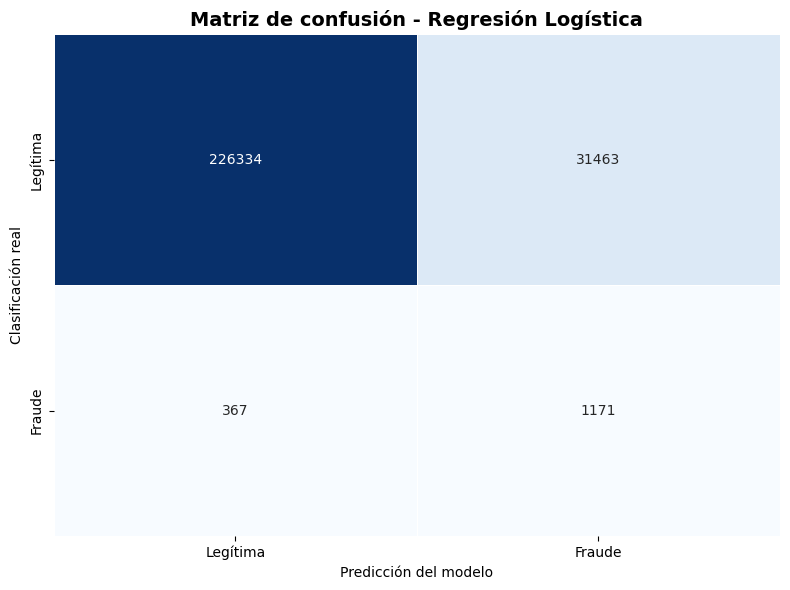

Gráfico guardado correctamente.


In [45]:

# PASO 11: Visualización de la matriz de confusión

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calcular matriz
matriz = confusion_matrix(
    y_validacion,
    predicciones_logistico,
    labels=[0, 1]
)

# Crear gráfico
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legítima", "Fraude"],
    yticklabels=["Legítima", "Fraude"],
    linewidths=0.5,
    cbar=False
)

plt.title(
    "Matriz de confusión - Regresión Logística",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicción del modelo")
plt.ylabel("Clasificación real")


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "02_matriz_confusion_logistica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")



## 12. Simulación de umbrales de detección de fraude

### 12.1. Evaluación de diferentes umbrales de clasificación

Los modelos predictivos de clasificación permiten establecer diferentes umbrales para determinar cuándo una transacción debe considerarse sospechosa.

En esta etapa se simulará el comportamiento del modelo de Regresión Logística utilizando umbrales de 0.30, 0.40, 0.50, 0.60, 0.70, 0.80 y 0.90.

Para cada escenario se calcularán:

- Cantidad total de alertas generadas.
- Fraudes detectados.
- Fraudes no detectados.
- Falsos positivos.
- Precision.
- Recall.
- F1-Score.

El objetivo consiste en analizar cómo cambia el comportamiento del sistema ante diferentes niveles de exigencia y determinar qué configuraciones podrían ofrecer un equilibrio adecuado entre detección de fraude y generación de falsas alertas.

Esta simulación se realizará sobre el conjunto de validación, sin modificar el modelo entrenado ni utilizar el conjunto reservado para prueba final.


In [16]:

# PASO 12: Simulación de diferentes umbrales

umbrales = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

resultados_umbrales = []

for umbral in umbrales:

    # Predicciones según el umbral
    predicciones = (
        probabilidades_logistico >= umbral
    ).astype(int)

    # Matriz de confusión
    tn, fp, fn, tp = confusion_matrix(
        y_validacion,
        predicciones,
        labels=[0, 1]
    ).ravel()

    # Métricas
    precision = precision_score(
        y_validacion, predicciones,
        zero_division=0
    )

    recall = recall_score(
        y_validacion, predicciones,
        zero_division=0
    )

    f1 = f1_score(
        y_validacion, predicciones,
        zero_division=0
    )

    # Guardar resultados
    resultados_umbrales.append({
        "Umbral": umbral,
        "Alertas": int(predicciones.sum()),
        "Fraudes detectados": int(tp),
        "Fraudes no detectados": int(fn),
        "Falsos positivos": int(fp),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2)
    })

# Crear tabla de comparación
df_umbrales = pd.DataFrame(resultados_umbrales)

print("SIMULACIÓN DE UMBRALES DE RIESGO")

display(df_umbrales)


SIMULACIÓN DE UMBRALES DE RIESGO


,Umbral,Alertas,Fraudes detectados,Fraudes no detectados,Falsos positivos,Precision (%),Recall (%),F1-Score (%)
0,0.3,83881,1335,203,82546,1.59,86.80,3.13
1,0.4,55069,1225,313,53844,2.22,79.65,4.33
2,0.5,32634,1171,367,31463,3.59,76.14,6.85
3,0.6,15871,1140,398,14731,7.18,74.12,13.10
4,0.7,6776,1122,416,5654,16.56,72.95,26.99
5,0.8,4214,1017,521,3197,24.13,66.12,35.36
6,0.9,3171,788,750,2383,24.85,51.24,33.47



## 13. Análisis gráfico de los umbrales de clasificación

Con el propósito de evaluar el comportamiento operativo del modelo de Regresión Logística, se comparan gráficamente los resultados obtenidos mediante diferentes umbrales de clasificación.

Se analizarán tres aspectos fundamentales:

1. La relación entre Precision y Recall.
2. La evolución de las falsas alertas generadas.
3. La cantidad de fraudes detectados y no detectados.

Estas visualizaciones permitirán identificar los compromisos existentes entre una mayor capacidad de detección y una menor carga operativa.

Los resultados servirán como referencia para seleccionar posteriormente un umbral de clasificación y comparar el modelo predictivo con las reglas tradicionales desarrolladas durante el Midterm.


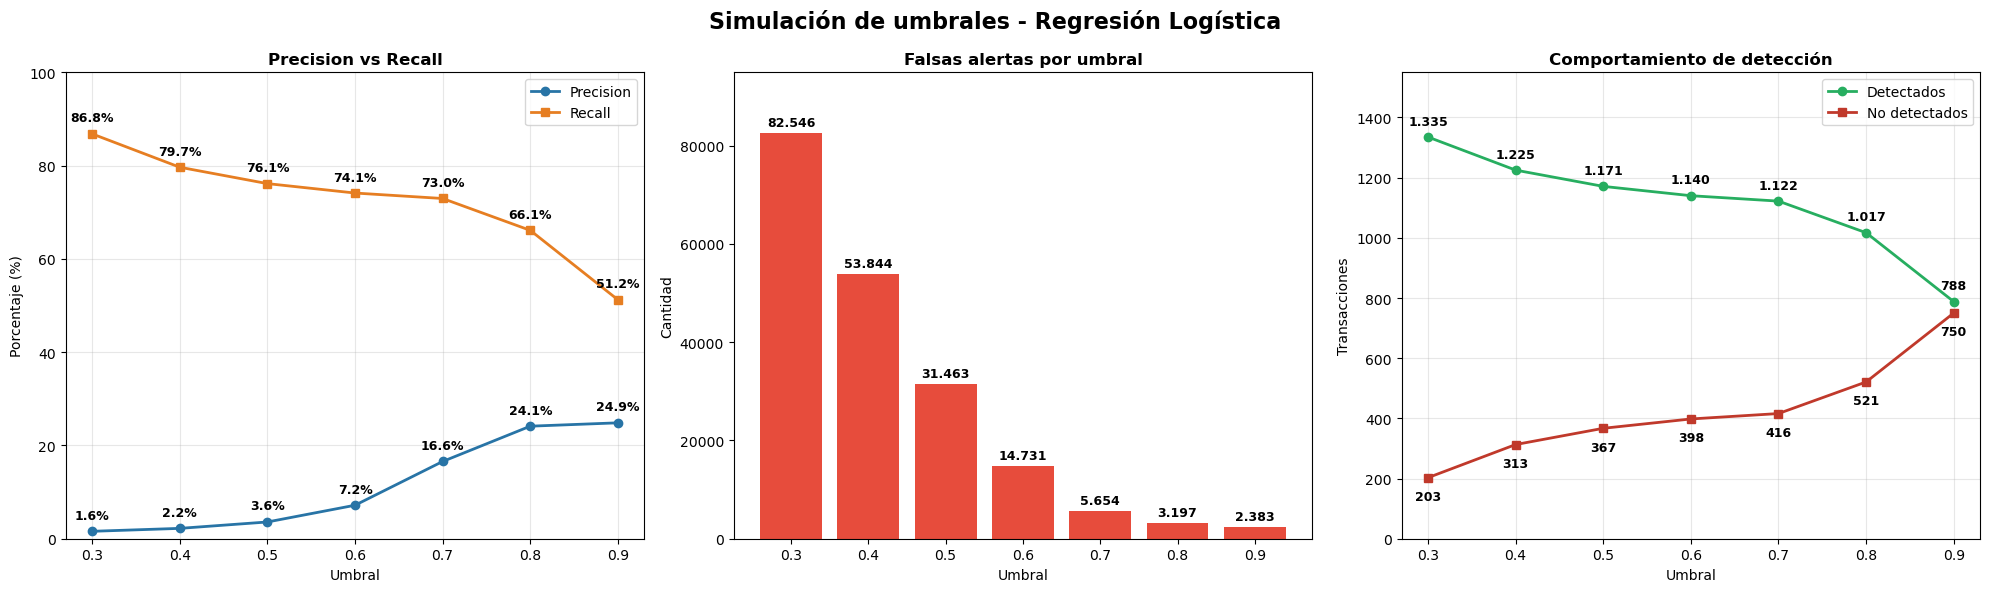

Gráfico guardado correctamente.


In [46]:

# PASO 13: Comparación gráfica de umbrales CON ETIQUETAS

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

umbrales = df_umbrales["Umbral"]

# ==========================================
# GRÁFICO 1: PRECISION Y RECALL
# ==========================================

axes[0].plot(
    umbrales,
    df_umbrales["Precision (%)"],
    marker="o",
    linewidth=2,
    color="#2874A6",
    label="Precision"
)

axes[0].plot(
    umbrales,
    df_umbrales["Recall (%)"],
    marker="s",
    linewidth=2,
    color="#E67E22",
    label="Recall"
)

# Etiquetas de Precision
for x, y in zip(
    umbrales, df_umbrales["Precision (%)"]
):
    axes[0].annotate(
        f"{y:.1f}%",
        (x, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# Etiquetas de Recall
for x, y in zip(
    umbrales, df_umbrales["Recall (%)"]
):
    axes[0].annotate(
        f"{y:.1f}%",
        (x, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

axes[0].set_title(
    "Precision vs Recall",
    fontweight="bold"
)
axes[0].set_xlabel("Umbral")
axes[0].set_ylabel("Porcentaje (%)")
axes[0].set_ylim(0, 100)
axes[0].legend()
axes[0].grid(alpha=0.3)

# ==========================================
# GRÁFICO 2: FALSAS ALERTAS
# ==========================================

barras = axes[1].bar(
    umbrales.round(2).astype(str),
    df_umbrales["Falsos positivos"],
    color="#E74C3C"
)

for barra in barras:
    altura = barra.get_height()

    axes[1].annotate(
        f"{int(altura):,}".replace(",", "."),
        (
            barra.get_x() + barra.get_width()/2,
            altura
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

axes[1].set_title(
    "Falsas alertas por umbral",
    fontweight="bold"
)
axes[1].set_xlabel("Umbral")
axes[1].set_ylabel("Cantidad")
axes[1].set_ylim(
    0,
    df_umbrales["Falsos positivos"].max() * 1.15
)

# ==========================================
# GRÁFICO 3: DETECCIÓN DE FRAUDES
# ==========================================

axes[2].plot(
    umbrales,
    df_umbrales["Fraudes detectados"],
    marker="o",
    linewidth=2,
    color="#27AE60",
    label="Detectados"
)

axes[2].plot(
    umbrales,
    df_umbrales["Fraudes no detectados"],
    marker="s",
    linewidth=2,
    color="#C0392B",
    label="No detectados"
)

# Etiquetas fraudes detectados
for x, y in zip(
    umbrales,
    df_umbrales["Fraudes detectados"]
):
    axes[2].annotate(
        f"{y:,}".replace(",", "."),
        (x, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# Etiquetas fraudes no detectados
for x, y in zip(
    umbrales,
    df_umbrales["Fraudes no detectados"]
):
    axes[2].annotate(
        f"{y:,}".replace(",", "."),
        (x, y),
        xytext=(0, -16),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

axes[2].set_title(
    "Comportamiento de detección",
    fontweight="bold"
)
axes[2].set_xlabel("Umbral")
axes[2].set_ylabel("Transacciones")
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_ylim(0, 1550)

# ==========================================
# TÍTULO GENERAL
# ==========================================

plt.suptitle(
    "Simulación de umbrales - Regresión Logística",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "03_umbrales_logistica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")



## 14. Entrenamiento del segundo modelo predictivo

### 14.1. Árbol de Decisión

En esta etapa se implementará un segundo modelo de clasificación supervisada mediante el algoritmo de Árbol de Decisión (Decision Tree).

Este algoritmo permite identificar patrones a partir de divisiones sucesivas de las características transaccionales, construyendo reglas de clasificación aprendidas directamente de los datos históricos.

Para el entrenamiento se utilizará el mismo conjunto empleado en la Regresión Logística, con el propósito de realizar posteriormente una comparación bajo condiciones equivalentes.

Se establecerán restricciones sobre la profundidad del árbol y la cantidad mínima de observaciones por hoja, con el objetivo de reducir el riesgo de sobreajuste.

También se considerará el desbalance de clases mediante ponderaciones durante el entrenamiento.

El desempeño será evaluado posteriormente sobre el conjunto de validación, sin utilizar todavía los datos de prueba final.


In [20]:

# PASO 14: Entrenamiento del Árbol de Decisión

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import time

# Crear modelo de Árbol de Decisión
modelo_arbol = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador)),
        (
            "clasificador",
            DecisionTreeClassifier(
                max_depth=10,
                min_samples_leaf=50,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("INICIANDO ENTRENAMIENTO")
print("Modelo: Árbol de Decisión")
print("Transacciones:", len(X_entrenamiento))

# Medir tiempo de entrenamiento
inicio = time.time()

# Entrenar el modelo
modelo_arbol.fit(
    X_entrenamiento,
    y_entrenamiento
)

fin = time.time()

# Mostrar resultados
print("\nENTRENAMIENTO FINALIZADO")

print(
    "Tiempo de entrenamiento:",
    round(fin - inicio, 2),
    "segundos"
)

print(
    "Profundidad del árbol:",
    modelo_arbol.named_steps[
        "clasificador"
    ].get_depth()
)

print(
    "Número de hojas:",
    modelo_arbol.named_steps[
        "clasificador"
    ].get_n_leaves()
)

print("\nModelo de Árbol de Decisión entrenado correctamente.")


INICIANDO ENTRENAMIENTO
Modelo: Árbol de Decisión
Transacciones: 1037340

ENTRENAMIENTO FINALIZADO
Tiempo de entrenamiento: 22.27 segundos
Profundidad del árbol: 10
Número de hojas: 179

Modelo de Árbol de Decisión entrenado correctamente.



## 15. Evaluación del modelo de Árbol de Decisión

### 15.1. Predicción sobre el conjunto de validación

Una vez entrenado el modelo de Árbol de Decisión, se evaluará su desempeño utilizando el conjunto de validación, compuesto por 259.335 transacciones.

La evaluación se realizará sobre los mismos datos empleados para analizar la Regresión Logística, con la finalidad de mantener condiciones comparables.

Se calcularán las siguientes métricas:

- **Accuracy:** porcentaje total de predicciones correctas.
- **Precision:** proporción de alertas que corresponden a fraudes reales.
- **Recall:** porcentaje de fraudes reales identificados.
- **F1-Score:** equilibrio entre Precision y Recall.
- **Matriz de confusión:** clasificación de verdaderos negativos, falsos positivos, falsos negativos y verdaderos positivos.

Se utilizará inicialmente un umbral de clasificación de 0.50, que permitirá establecer una referencia para comparar los modelos.

Los resultados servirán para determinar si el Árbol de Decisión ofrece ventajas frente a la Regresión Logística en términos de detección de fraude y reducción de falsas alertas.


In [21]:

# PASO 15: Evaluación del Árbol de Decisión

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Obtener puntuaciones de fraude
probabilidades_arbol = modelo_arbol.predict_proba(
    X_validacion
)[:, 1]

# Generar predicciones con umbral de 0.50
predicciones_arbol = (
    probabilidades_arbol >= 0.50
).astype(int)

# Calcular métricas
accuracy_arbol = accuracy_score(
    y_validacion, predicciones_arbol
)

precision_arbol = precision_score(
    y_validacion, predicciones_arbol,
    zero_division=0
)

recall_arbol = recall_score(
    y_validacion, predicciones_arbol,
    zero_division=0
)

f1_arbol = f1_score(
    y_validacion, predicciones_arbol,
    zero_division=0
)

# Calcular matriz de confusión
tn_a, fp_a, fn_a, tp_a = confusion_matrix(
    y_validacion,
    predicciones_arbol,
    labels=[0, 1]
).ravel()

# Mostrar resultados
print("EVALUACIÓN DEL MODELO - ÁRBOL DE DECISIÓN")

print("\nMÉTRICAS DE DESEMPEÑO")
print(f"Accuracy:  {accuracy_arbol:.4f}")
print(f"Precision: {precision_arbol:.4f}")
print(f"Recall:    {recall_arbol:.4f}")
print(f"F1-Score:  {f1_arbol:.4f}")

print("\nRESULTADOS DE CLASIFICACIÓN")
print("Verdaderos negativos:", tn_a)
print("Falsos positivos:", fp_a)
print("Falsos negativos:", fn_a)
print("Verdaderos positivos:", tp_a)

print("\nRESUMEN OPERATIVO")
print("Transacciones evaluadas:", len(y_validacion))
print("Fraudes reales:", int(y_validacion.sum()))
print("Alertas generadas:", int(predicciones_arbol.sum()))
print("Fraudes detectados:", tp_a)
print("Fraudes no detectados:", fn_a)
print("Alertas falsas:", fp_a)


EVALUACIÓN DEL MODELO - ÁRBOL DE DECISIÓN

MÉTRICAS DE DESEMPEÑO
Accuracy:  0.9613
Precision: 0.1308
Recall:    0.9785
F1-Score:  0.2308

RESULTADOS DE CLASIFICACIÓN
Verdaderos negativos: 247800
Falsos positivos: 9997
Falsos negativos: 33
Verdaderos positivos: 1505

RESUMEN OPERATIVO
Transacciones evaluadas: 259335
Fraudes reales: 1538
Alertas generadas: 11502
Fraudes detectados: 1505
Fraudes no detectados: 33
Alertas falsas: 9997



## 16. Comparación de modelos predictivos

### 16.1. Regresión Logística vs. Árbol de Decisión

En esta etapa se comparan los resultados obtenidos mediante los modelos de Regresión Logística y Árbol de Decisión, utilizando el mismo conjunto de validación y un umbral inicial de clasificación de 0.50.

La comparación considera tres dimensiones:

1. **Desempeño predictivo:** Precision, Recall y F1-Score.
2. **Capacidad de detección:** cantidad de fraudes detectados y no detectados.
3. **Impacto operativo:** número de falsas alertas generadas.

El objetivo es identificar cuál de los modelos presenta un mejor equilibrio entre capacidad de detección y generación de alertas.

Los resultados corresponden al conjunto de validación y serán contrastados posteriormente con otros algoritmos y con las reglas desarrolladas durante el Midterm.


COMPARACIÓN DE MODELOS PREDICTIVOS


,Modelo,Precision (%),Recall (%),F1-Score (%),Fraudes detectados,Fraudes no detectados,Falsos positivos
0,Regresión Logística,3.59,76.14,6.85,1171,367,31463
1,Árbol de Decisión,13.08,97.85,23.08,1505,33,9997


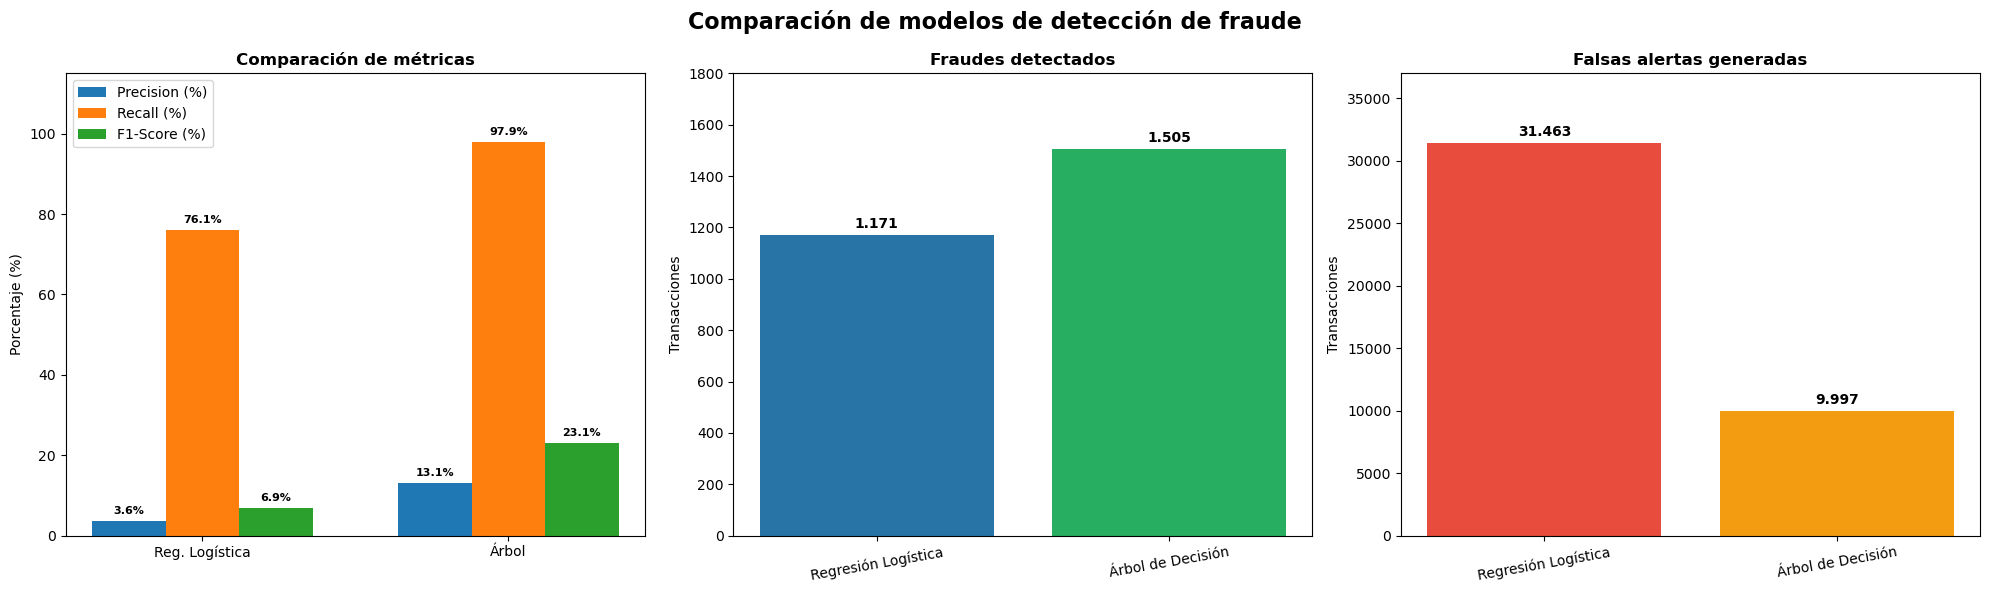

Gráfico guardado correctamente.


In [49]:

# PASO 16: Comparación gráfica de modelos

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Construir tabla comparativa usando los resultados reales
comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Árbol de Decisión"
    ],
    "Precision (%)": [
        precision_score(y_validacion, predicciones_logistico) * 100,
        precision_arbol * 100
    ],
    "Recall (%)": [
        recall_score(y_validacion, predicciones_logistico) * 100,
        recall_arbol * 100
    ],
    "F1-Score (%)": [
        f1_score(y_validacion, predicciones_logistico) * 100,
        f1_arbol * 100
    ],
    "Fraudes detectados": [
        1171,
        int(tp_a)
    ],
    "Fraudes no detectados": [
        367,
        int(fn_a)
    ],
    "Falsos positivos": [
        31463,
        int(fp_a)
    ]
})

print("COMPARACIÓN DE MODELOS PREDICTIVOS")
display(comparacion_modelos.round(2))

# Crear gráficos
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

modelos = comparacion_modelos["Modelo"]
x = np.arange(len(modelos))

# GRÁFICO 1: MÉTRICAS DE DESEMPEÑO

metricas = [
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

ancho = 0.24

for i, metrica in enumerate(metricas):

    barras = axes[0].bar(
        x + (i - 1) * ancho,
        comparacion_modelos[metrica],
        width=ancho,
        label=metrica
    )

    for barra in barras:
        altura = barra.get_height()

        axes[0].annotate(
            f"{altura:.1f}%",
            (
                barra.get_x() + barra.get_width()/2,
                altura
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            fontweight="bold"
        )

axes[0].set_title(
    "Comparación de métricas",
    fontweight="bold"
)
axes[0].set_ylabel("Porcentaje (%)")
axes[0].set_xticks(x, ["Reg. Logística", "Árbol"])
axes[0].set_ylim(0, 115)
axes[0].legend()

# GRÁFICO 2: FRAUDES DETECTADOS

barras = axes[1].bar(
    modelos,
    comparacion_modelos["Fraudes detectados"],
    color=["#2874A6", "#27AE60"]
)

for barra in barras:
    altura = barra.get_height()

    axes[1].annotate(
        f"{int(altura):,}".replace(",", "."),
        (
            barra.get_x() + barra.get_width()/2,
            altura
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_title(
    "Fraudes detectados",
    fontweight="bold"
)
axes[1].set_ylabel("Transacciones")
axes[1].set_ylim(0, 1800)
axes[1].tick_params(axis="x", rotation=10)

# GRÁFICO 3: FALSAS ALERTAS

barras = axes[2].bar(
    modelos,
    comparacion_modelos["Falsos positivos"],
    color=["#E74C3C", "#F39C12"]
)

for barra in barras:
    altura = barra.get_height()

    axes[2].annotate(
        f"{int(altura):,}".replace(",", "."),
        (
            barra.get_x() + barra.get_width()/2,
            altura
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

axes[2].set_title(
    "Falsas alertas generadas",
    fontweight="bold"
)
axes[2].set_ylabel("Transacciones")
axes[2].set_ylim(0, 37000)
axes[2].tick_params(axis="x", rotation=10)

plt.suptitle(
    "Comparación de modelos de detección de fraude",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "04_logistica_vs_arbol.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")




## 17. Entrenamiento del tercer modelo predictivo

### 17.1. Random Forest (Bosque Aleatorio)

En esta etapa se implementará el algoritmo Random Forest, una técnica de aprendizaje supervisado basada en la combinación de múltiples árboles de decisión.

El objetivo es evaluar si un conjunto de árboles permite mejorar la capacidad de detección de fraude y reducir la generación de falsas alertas frente a los modelos de Regresión Logística y Árbol de Decisión.

El entrenamiento se realizará utilizando las mismas variables predictivas y el mismo conjunto histórico de entrenamiento empleado en los modelos anteriores.

Se establecerán parámetros para controlar la complejidad del modelo y considerar el desbalance existente entre transacciones legítimas y fraudulentas.

Posteriormente, el desempeño será evaluado sobre el conjunto de validación, manteniendo el conjunto de prueba independiente para la evaluación final.


In [23]:

# PASO 17: Entrenamiento de Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import time

# Configurar Random Forest
modelo_random_forest = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador)),
        (
            "clasificador",
            RandomForestClassifier(
                n_estimators=50,
                max_depth=12,
                min_samples_leaf=50,
                class_weight="balanced_subsample",
                n_jobs=2,
                random_state=42
            )
        )
    ]
)

print("INICIANDO ENTRENAMIENTO")
print("Modelo: Random Forest")
print("Transacciones:", len(X_entrenamiento))
print("Número de árboles: 50")

# Medir tiempo
inicio = time.time()

# Entrenar modelo
modelo_random_forest.fit(
    X_entrenamiento,
    y_entrenamiento
)

fin = time.time()

# Obtener clasificador entrenado
rf = modelo_random_forest.named_steps["clasificador"]

print("\nENTRENAMIENTO FINALIZADO")

print(
    "Tiempo de entrenamiento:",
    round(fin - inicio, 2),
    "segundos"
)

print("Árboles entrenados:", len(rf.estimators_))

print(
    "Profundidad máxima alcanzada:",
    max(arbol.get_depth() for arbol in rf.estimators_)
)

print("\nModelo Random Forest entrenado correctamente.")


INICIANDO ENTRENAMIENTO
Modelo: Random Forest
Transacciones: 1037340
Número de árboles: 50

ENTRENAMIENTO FINALIZADO
Tiempo de entrenamiento: 48.01 segundos
Árboles entrenados: 50
Profundidad máxima alcanzada: 12

Modelo Random Forest entrenado correctamente.



## 18. Evaluación del modelo Random Forest

### 18.1. Predicción sobre el conjunto de validación

Una vez entrenado el modelo Random Forest, se procederá a evaluar su desempeño utilizando el conjunto de validación, compuesto por 259.335 transacciones.

La evaluación se realizará utilizando un umbral inicial de clasificación de 0.50, manteniendo las mismas condiciones empleadas para los modelos de Regresión Logística y Árbol de Decisión.

Se calcularán las métricas Accuracy, Precision, Recall y F1-Score, así como los componentes de la matriz de confusión.

Adicionalmente, se analizará la cantidad de alertas generadas, fraudes detectados, fraudes no detectados y falsos positivos.

Los resultados permitirán determinar si Random Forest ofrece mejoras frente a los modelos anteriores y establecer una base para comparar posteriormente sus diferentes configuraciones y umbrales de riesgo.


In [24]:

# PASO 18: Evaluación del modelo Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score
)

# Obtener puntuaciones de riesgo
probabilidades_rf = modelo_random_forest.predict_proba(
    X_validacion
)[:, 1]

# Clasificar con umbral de 0.50
predicciones_rf = (
    probabilidades_rf >= 0.50
).astype(int)

# Calcular métricas
accuracy_rf = accuracy_score(
    y_validacion, predicciones_rf
)

precision_rf = precision_score(
    y_validacion, predicciones_rf,
    zero_division=0
)

recall_rf = recall_score(
    y_validacion, predicciones_rf,
    zero_division=0
)

f1_rf = f1_score(
    y_validacion, predicciones_rf,
    zero_division=0
)

# Área bajo la curva Precision-Recall
ap_rf = average_precision_score(
    y_validacion,
    probabilidades_rf
)

# Matriz de confusión
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(
    y_validacion,
    predicciones_rf,
    labels=[0, 1]
).ravel()

# Mostrar resultados
print("EVALUACIÓN DEL MODELO - RANDOM FOREST")

print("\nMÉTRICAS DE DESEMPEÑO")
print(f"Accuracy:       {accuracy_rf:.4f}")
print(f"Precision:      {precision_rf:.4f}")
print(f"Recall:         {recall_rf:.4f}")
print(f"F1-Score:       {f1_rf:.4f}")
print(f"Average Precision: {ap_rf:.4f}")

print("\nRESULTADOS DE CLASIFICACIÓN")
print("Verdaderos negativos:", tn_rf)
print("Falsos positivos:", fp_rf)
print("Falsos negativos:", fn_rf)
print("Verdaderos positivos:", tp_rf)

print("\nRESUMEN OPERATIVO")
print("Transacciones evaluadas:", len(y_validacion))
print("Fraudes reales:", int(y_validacion.sum()))
print("Alertas generadas:", int(predicciones_rf.sum()))
print("Fraudes detectados:", tp_rf)
print("Fraudes no detectados:", fn_rf)
print("Alertas falsas:", fp_rf)


EVALUACIÓN DEL MODELO - RANDOM FOREST

MÉTRICAS DE DESEMPEÑO
Accuracy:       0.9720
Precision:      0.1456
Recall:         0.7627
F1-Score:       0.2445
Average Precision: 0.6446

RESULTADOS DE CLASIFICACIÓN
Verdaderos negativos: 250913
Falsos positivos: 6884
Falsos negativos: 365
Verdaderos positivos: 1173

RESUMEN OPERATIVO
Transacciones evaluadas: 259335
Fraudes reales: 1538
Alertas generadas: 8057
Fraudes detectados: 1173
Fraudes no detectados: 365
Alertas falsas: 6884



## 19. Comparación integral de modelos predictivos

### 19.1. Regresión Logística, Árbol de Decisión y Random Forest

En esta etapa se realiza una comparación de los tres modelos de clasificación supervisada desarrollados para la detección de fraude en transacciones electrónicas.

La evaluación utiliza el mismo conjunto de validación, conformado por 259.335 transacciones, lo cual permite comparar los resultados bajo condiciones equivalentes.

Se analizarán las siguientes dimensiones:

1. **Capacidad de detección:** porcentaje y cantidad de fraudes identificados.
2. **Precisión de las alertas:** proporción de alertas que corresponden a fraudes reales.
3. **Eficiencia operativa:** cantidad de falsas alertas generadas.
4. **Desempeño general:** F1-Score y Average Precision.

Los indicadores permitirán identificar las fortalezas y limitaciones de cada algoritmo.

La comparación inicial utiliza un umbral de clasificación de 0.50. Posteriormente se evaluarán diferentes umbrales y escenarios operativos antes de seleccionar el modelo más conveniente.


COMPARACIÓN INTEGRAL DE MODELOS


,Modelo,Precision (%),Recall (%),F1-Score (%),Average Precision,Fraudes detectados,Fraudes no detectados,Falsos positivos,Alertas
0,Regresión Logística,3.588,76.138,6.854,0.168,1171,367,31463,32634
1,Árbol de Decisión,13.085,97.854,23.083,0.496,1505,33,9997,11502
2,Random Forest,14.559,76.268,24.450,0.645,1173,365,6884,8057


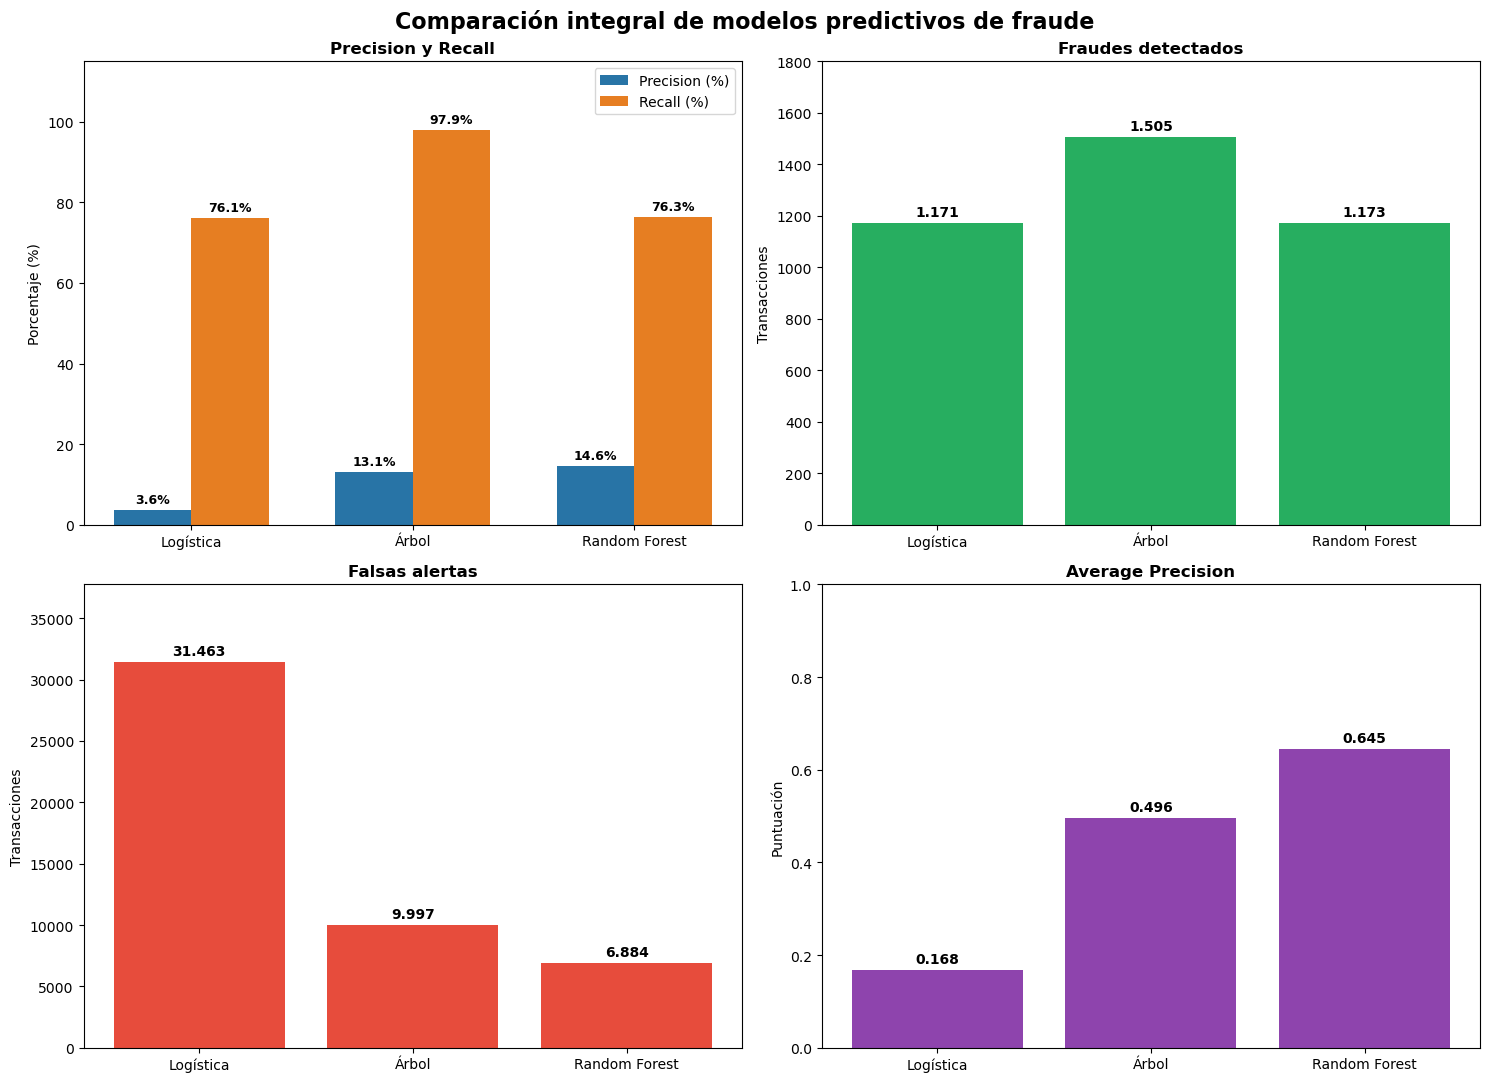

Gráfico guardado correctamente.


In [50]:

# PASO 19: Comparación integral de los tres modelos

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score
)

# Modelos y sus resultados de validación
modelos_evaluados = {
    "Regresión Logística": probabilidades_logistico,
    "Árbol de Decisión": probabilidades_arbol,
    "Random Forest": probabilidades_rf
}

resultados = []

for nombre, probabilidades in modelos_evaluados.items():

    predicciones = (probabilidades >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validacion,
        predicciones,
        labels=[0, 1]
    ).ravel()

    resultados.append({
        "Modelo": nombre,
        "Precision (%)": precision_score(
            y_validacion, predicciones,
            zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_validacion, predicciones,
            zero_division=0
        ) * 100,
        "F1-Score (%)": f1_score(
            y_validacion, predicciones,
            zero_division=0
        ) * 100,
        "Average Precision": average_precision_score(
            y_validacion, probabilidades
        ),
        "Fraudes detectados": int(tp),
        "Fraudes no detectados": int(fn),
        "Falsos positivos": int(fp),
        "Alertas": int(tp + fp)
    })

comparacion_final = pd.DataFrame(resultados)

print("COMPARACIÓN INTEGRAL DE MODELOS")
display(comparacion_final.round(3))

# Crear cuatro gráficos comparativos
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

nombres = comparacion_final["Modelo"]
x = np.arange(len(nombres))

# GRÁFICO 1: PRECISION Y RECALL
ancho = 0.35

for desplazamiento, columna, color in [
    (-ancho/2, "Precision (%)", "#2874A6"),
    (ancho/2, "Recall (%)", "#E67E22")
]:

    barras = axes[0, 0].bar(
        x + desplazamiento,
        comparacion_final[columna],
        width=ancho,
        color=color,
        label=columna
    )

    for barra in barras:
        axes[0, 0].annotate(
            f"{barra.get_height():.1f}%",
            (
                barra.get_x() + barra.get_width()/2,
                barra.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            fontweight="bold"
        )

axes[0, 0].set_title("Precision y Recall", fontweight="bold")
axes[0, 0].set_ylabel("Porcentaje (%)")
axes[0, 0].set_xticks(x, ["Logística", "Árbol", "Random Forest"])
axes[0, 0].set_ylim(0, 115)
axes[0, 0].legend()

# GRÁFICO 2: FRAUDES DETECTADOS
barras = axes[0, 1].bar(
    x,
    comparacion_final["Fraudes detectados"],
    color="#27AE60"
)

for barra in barras:
    axes[0, 1].annotate(
        f"{int(barra.get_height()):,}".replace(",", "."),
        (
            barra.get_x() + barra.get_width()/2,
            barra.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

axes[0, 1].set_title("Fraudes detectados", fontweight="bold")
axes[0, 1].set_ylabel("Transacciones")
axes[0, 1].set_xticks(x, ["Logística", "Árbol", "Random Forest"])
axes[0, 1].set_ylim(0, 1800)

# GRÁFICO 3: FALSAS ALERTAS
barras = axes[1, 0].bar(
    x,
    comparacion_final["Falsos positivos"],
    color="#E74C3C"
)

for barra in barras:
    axes[1, 0].annotate(
        f"{int(barra.get_height()):,}".replace(",", "."),
        (
            barra.get_x() + barra.get_width()/2,
            barra.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

axes[1, 0].set_title("Falsas alertas", fontweight="bold")
axes[1, 0].set_ylabel("Transacciones")
axes[1, 0].set_xticks(x, ["Logística", "Árbol", "Random Forest"])
axes[1, 0].set_ylim(
    0,
    comparacion_final["Falsos positivos"].max() * 1.2
)

# GRÁFICO 4: AVERAGE PRECISION
barras = axes[1, 1].bar(
    x,
    comparacion_final["Average Precision"],
    color="#8E44AD"
)

for barra in barras:
    axes[1, 1].annotate(
        f"{barra.get_height():.3f}",
        (
            barra.get_x() + barra.get_width()/2,
            barra.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

axes[1, 1].set_title("Average Precision", fontweight="bold")
axes[1, 1].set_ylabel("Puntuación")
axes[1, 1].set_xticks(x, ["Logística", "Árbol", "Random Forest"])
axes[1, 1].set_ylim(0, 1)

plt.suptitle(
    "Comparación integral de modelos predictivos de fraude",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "05_comparacion_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")




## 20. Simulación comparativa de umbrales de riesgo

### 20.1. Evaluación de Árbol de Decisión y Random Forest

Con el propósito de analizar el comportamiento operativo de los modelos predictivos, se evaluarán diferentes umbrales de clasificación para los algoritmos Árbol de Decisión y Random Forest.

Se utilizarán umbrales comprendidos entre 0.10 y 0.90.

Para cada escenario se calcularán:

- Cantidad de alertas generadas.
- Fraudes detectados.
- Fraudes no detectados.
- Falsos positivos.
- Precision.
- Recall.
- F1-Score.

El análisis permitirá estudiar la relación entre el umbral de clasificación, la capacidad de detección y la generación de falsas alertas.

Las simulaciones se realizarán sobre el conjunto de validación, manteniendo reservado el conjunto de prueba para la evaluación final.

Las puntuaciones generadas por los modelos se interpretarán como indicadores de riesgo y no necesariamente como probabilidades calibradas de fraude.


In [27]:

# PASO 20: Simulación de umbrales para dos modelos

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

# Modelos a evaluar
modelos_simulacion = {
    "Árbol de Decisión": probabilidades_arbol,
    "Random Forest": probabilidades_rf
}

# Umbrales de riesgo
umbrales_simulacion = [
    0.10, 0.20, 0.30, 0.40, 0.50,
    0.60, 0.70, 0.80, 0.90
]

resultados_simulacion = []

# Evaluar cada modelo
for nombre, probabilidades in modelos_simulacion.items():

    for umbral in umbrales_simulacion:

        # Clasificar transacciones
        predicciones = (
            probabilidades >= umbral
        ).astype(int)

        # Matriz de confusión
        tn, fp, fn, tp = confusion_matrix(
            y_validacion,
            predicciones,
            labels=[0, 1]
        ).ravel()

        # Calcular métricas
        precision = precision_score(
            y_validacion,
            predicciones,
            zero_division=0
        )

        recall = recall_score(
            y_validacion,
            predicciones,
            zero_division=0
        )

        f1 = f1_score(
            y_validacion,
            predicciones,
            zero_division=0
        )

        resultados_simulacion.append({
            "Modelo": nombre,
            "Umbral": umbral,
            "Alertas": int(tp + fp),
            "Fraudes detectados": int(tp),
            "Fraudes no detectados": int(fn),
            "Falsos positivos": int(fp),
            "Precision (%)": round(precision * 100, 2),
            "Recall (%)": round(recall * 100, 2),
            "F1-Score (%)": round(f1 * 100, 2)
        })

# Crear tabla
df_simulacion = pd.DataFrame(
    resultados_simulacion
)

print("SIMULACIÓN DE UMBRALES - ÁRBOL Y RANDOM FOREST")

display(df_simulacion)


SIMULACIÓN DE UMBRALES - ÁRBOL Y RANDOM FOREST


,Modelo,Umbral,Alertas,Fraudes detectados,Fraudes no detectados,Falsos positivos,Precision (%),Recall (%),F1-Score (%)
0,Árbol de Decisión,0.1,14292,1513,25,12779,10.59,98.37,19.12
1,Árbol de Decisión,0.2,12782,1511,27,11271,11.82,98.24,21.10
2,Árbol de Decisión,0.3,12121,1509,29,10612,12.45,98.11,22.10
3,Árbol de Decisión,0.4,11502,1505,33,9997,13.08,97.85,23.08
4,Árbol de Decisión,0.5,11502,1505,33,9997,13.08,97.85,23.08
5,Árbol de Decisión,0.6,10364,1496,42,8868,14.43,97.27,25.14
6,Árbol de Decisión,0.7,7637,1479,59,6158,19.37,96.16,32.24
7,Árbol de Decisión,0.8,7284,1469,69,5815,20.17,95.51,33.30
8,Árbol de Decisión,0.9,6731,1460,78,5271,21.69,94.93,35.31
9,Random Forest,0.1,259335,1538,0,257797,0.59,100.00,1.18



## 21. Comparación gráfica de escenarios de riesgo

En esta etapa se representa gráficamente el comportamiento de los modelos Árbol de Decisión y Random Forest frente a diferentes umbrales de clasificación.

El análisis contempla cuatro dimensiones:

1. Evolución del Recall de ambos modelos.
2. Evolución de Precision.
3. Cantidad de falsas alertas generadas.
4. Cantidad de fraudes detectados.

El propósito es identificar las diferencias operativas entre los algoritmos y analizar cómo la modificación de los umbrales influye en la capacidad de detección y en el volumen de alertas.

Estas visualizaciones constituyen una simulación retrospectiva sobre datos históricos y no representan la activación real de reglas en un sistema transaccional.


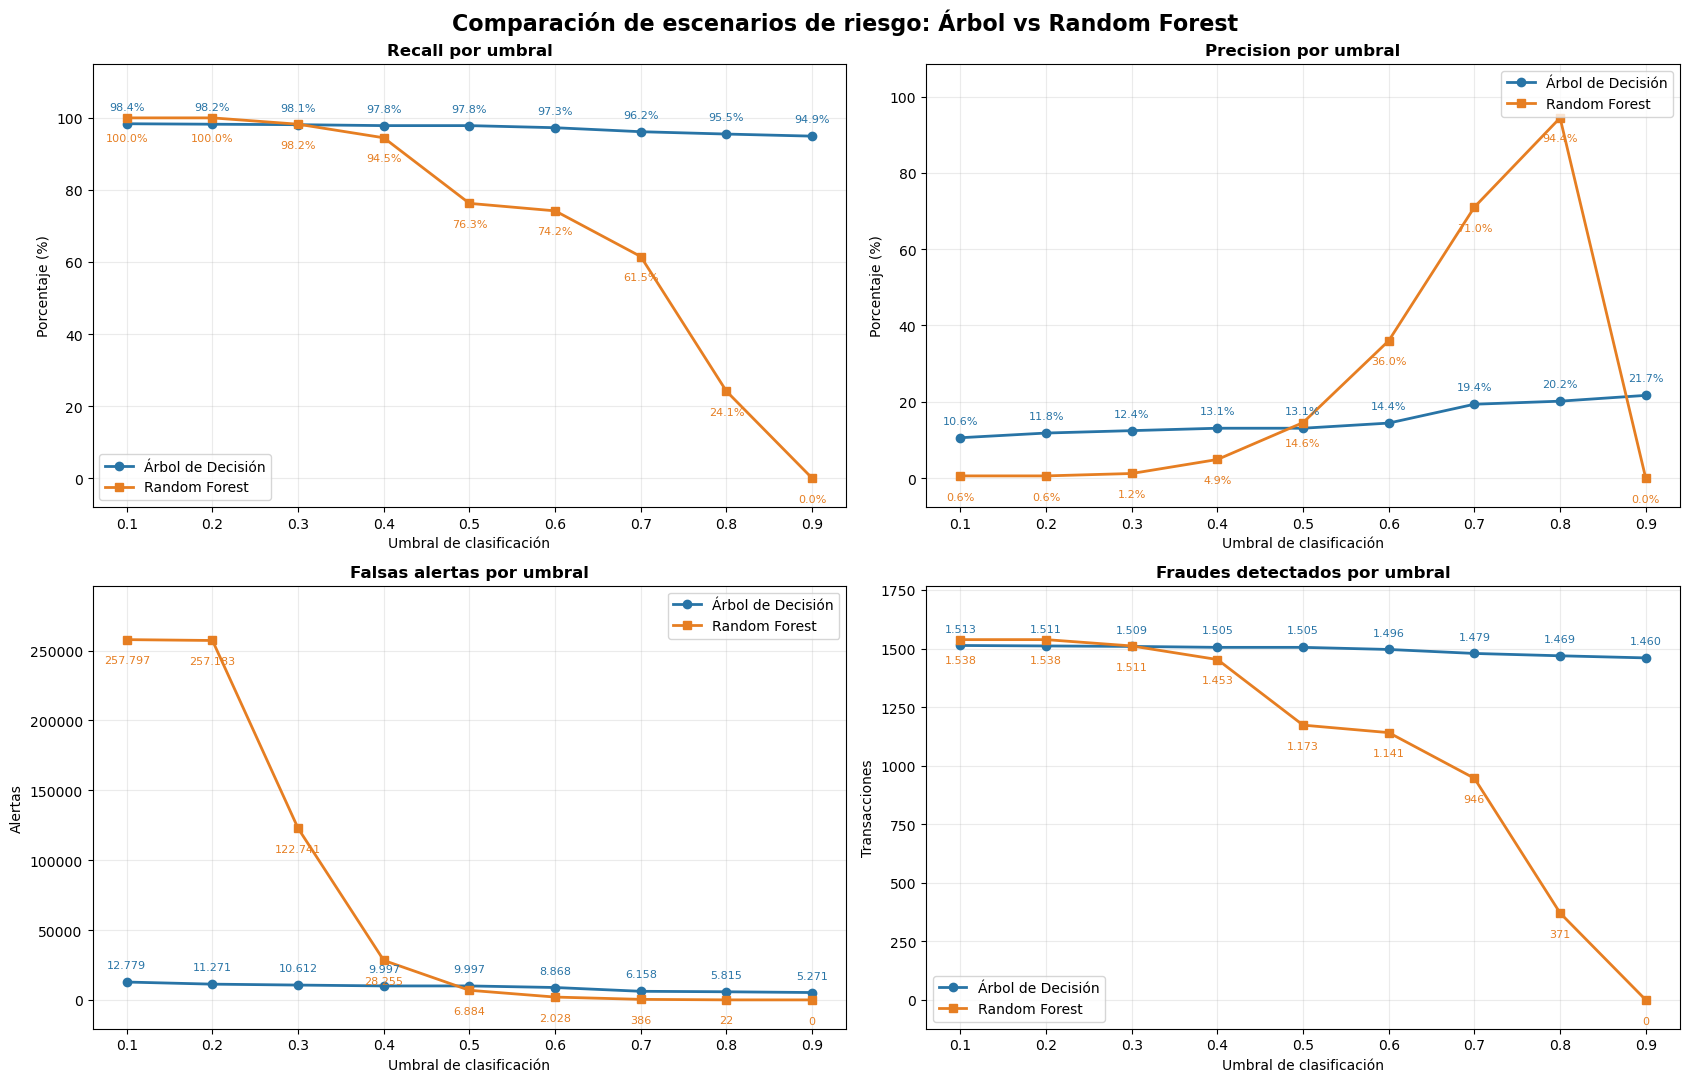

Gráfico guardado correctamente.


In [51]:

# PASO 21: Gráficos comparativos de umbrales

import matplotlib.pyplot as plt

# Separar resultados por modelo
df_arbol = df_simulacion[
    df_simulacion["Modelo"] == "Árbol de Decisión"
].copy()

df_rf = df_simulacion[
    df_simulacion["Modelo"] == "Random Forest"
].copy()

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

configuracion = [
    ("Recall (%)", "Recall por umbral", "Porcentaje (%)"),
    ("Precision (%)", "Precision por umbral", "Porcentaje (%)"),
    ("Falsos positivos", "Falsas alertas por umbral", "Alertas"),
    ("Fraudes detectados", "Fraudes detectados por umbral", "Transacciones")
]

for ax, (columna, titulo, ylabel) in zip(
    axes.flat, configuracion
):

    ax.plot(
        df_arbol["Umbral"],
        df_arbol[columna],
        marker="o",
        linewidth=2,
        color="#2874A6",
        label="Árbol de Decisión"
    )

    ax.plot(
        df_rf["Umbral"],
        df_rf[columna],
        marker="s",
        linewidth=2,
        color="#E67E22",
        label="Random Forest"
    )

    # Etiquetas para Árbol de Decisión
    for x, y in zip(df_arbol["Umbral"], df_arbol[columna]):

        etiqueta = (
            f"{y:.1f}%"
            if "(%)" in columna
            else f"{int(y):,}".replace(",", ".")
        )

        ax.annotate(
            etiqueta,
            (x, y),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color="#2874A6"
        )

    # Etiquetas para Random Forest
    for x, y in zip(df_rf["Umbral"], df_rf[columna]):

        etiqueta = (
            f"{y:.1f}%"
            if "(%)" in columna
            else f"{int(y):,}".replace(",", ".")
        )

        ax.annotate(
            etiqueta,
            (x, y),
            xytext=(0, -17),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color="#E67E22"
        )

    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Umbral de clasificación")
    ax.set_ylabel(ylabel)
    ax.set_xticks(df_arbol["Umbral"])
    ax.grid(alpha=0.25)
    ax.legend()

    # Margen para mostrar las etiquetas
    limite = max(df_arbol[columna].max(), df_rf[columna].max())

    ax.set_ylim(
        -limite * 0.08,
        limite * 1.15
    )

plt.suptitle(
    "Comparación de escenarios de riesgo: Árbol vs Random Forest",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "06_umbrales_arbol_rf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")




## 22. Simulación de capacidad fija de revisión de alertas

### 22.1. Comparación mediante Top-K

En esta etapa se evaluará el desempeño de los modelos predictivos bajo una restricción operativa común.

Se utilizará la metodología Top-K, que consiste en ordenar las transacciones según la puntuación de riesgo asignada por cada modelo y seleccionar una cantidad fija de operaciones prioritarias.

Se simularán capacidades de revisión de 1.000, 3.000, 5.000 y 10.000 alertas durante el periodo de validación.

Para cada modelo y escenario se calcularán:

- Fraudes detectados.
- Fraudes no detectados.
- Falsas alertas.
- Precision@K.
- Recall@K.

Esta metodología permite comparar los modelos bajo una misma capacidad de revisión, evitando que las diferencias entre sus umbrales de clasificación distorsionen la comparación.

Los resultados representan una simulación retrospectiva, no una implementación operativa en tiempo real.


In [30]:

# PASO 22: Simulación Top-K de capacidad operativa

import numpy as np
import pandas as pd

# Modelos entrenados
modelos_topk = {
    "Regresión Logística": probabilidades_logistico,
    "Árbol de Decisión": probabilidades_arbol,
    "Random Forest": probabilidades_rf
}

# Capacidades hipotéticas de revisión
capacidades = [1000, 3000, 5000, 10000]

# Etiquetas reales
y_real = np.asarray(y_validacion)

total_fraudes = int(y_real.sum())

resultados_topk = []

for nombre, puntuaciones in modelos_topk.items():

    puntuaciones = np.asarray(puntuaciones)

    # Ordenar transacciones de mayor a menor riesgo.
    # Orden estable para mantener un criterio reproducible
    # cuando existen puntuaciones iguales.
    orden = np.argsort(-puntuaciones, kind="stable")

    for k in capacidades:

        # Seleccionar las primeras K transacciones
        indices_topk = orden[:k]

        # Contar fraudes reales dentro del Top-K
        fraudes_detectados = int(
            y_real[indices_topk].sum()
        )

        falsas_alertas = k - fraudes_detectados

        fraudes_no_detectados = (
            total_fraudes - fraudes_detectados
        )

        precision_k = (
            fraudes_detectados / k * 100
        )

        recall_k = (
            fraudes_detectados / total_fraudes * 100
        )

        resultados_topk.append({
            "Modelo": nombre,
            "Capacidad": k,
            "Fraudes detectados": fraudes_detectados,
            "Fraudes no detectados": fraudes_no_detectados,
            "Falsas alertas": falsas_alertas,
            "Precision@K (%)": round(precision_k, 2),
            "Recall@K (%)": round(recall_k, 2)
        })

# Crear tabla comparativa
df_topk = pd.DataFrame(resultados_topk)

print("SIMULACIÓN DE CAPACIDAD FIJA DE ALERTAS")

display(
    df_topk.sort_values(
        ["Capacidad", "Fraudes detectados"],
        ascending=[True, False]
    ).reset_index(drop=True)
)


SIMULACIÓN DE CAPACIDAD FIJA DE ALERTAS


,Modelo,Capacidad,Fraudes detectados,Fraudes no detectados,Falsas alertas,Precision@K (%),Recall@K (%)
0,Random Forest,1000,820,718,180,82.00,53.32
1,Árbol de Decisión,1000,671,867,329,67.10,43.63
2,Regresión Logística,1000,191,1347,809,19.10,12.42
3,Random Forest,3000,1134,404,1866,37.80,73.73
4,Árbol de Decisión,3000,1025,513,1975,34.17,66.64
5,Regresión Logística,3000,744,794,2256,24.80,48.37
6,Árbol de Decisión,5000,1294,244,3706,25.88,84.14
7,Random Forest,5000,1162,376,3838,23.24,75.55
8,Regresión Logística,5000,1089,449,3911,21.78,70.81
9,Árbol de Decisión,10000,1494,44,8506,14.94,97.14



## 23. Comparación gráfica de desempeño Top-K

En esta etapa se realiza una comparación gráfica del desempeño de los modelos de Regresión Logística, Árbol de Decisión y Random Forest bajo diferentes capacidades de revisión de alertas.

Se utilizarán los resultados obtenidos mediante la simulación Top-K, considerando capacidades de 1.000, 3.000, 5.000 y 10.000 transacciones.

El análisis contempla:

1. **Precision@K:** proporción de fraudes reales entre las transacciones seleccionadas.
2. **Recall@K:** proporción de fraudes identificados respecto al total de fraudes existentes.
3. **Fraudes detectados:** número de operaciones fraudulentas identificadas según la capacidad de revisión.

Los gráficos permitirán identificar qué algoritmo aprovecha mejor una capacidad operativa limitada y cómo cambia su desempeño a medida que aumenta el número de alertas revisadas.

Los resultados corresponden a una simulación retrospectiva sobre el conjunto de validación y no representan una implementación en producción.


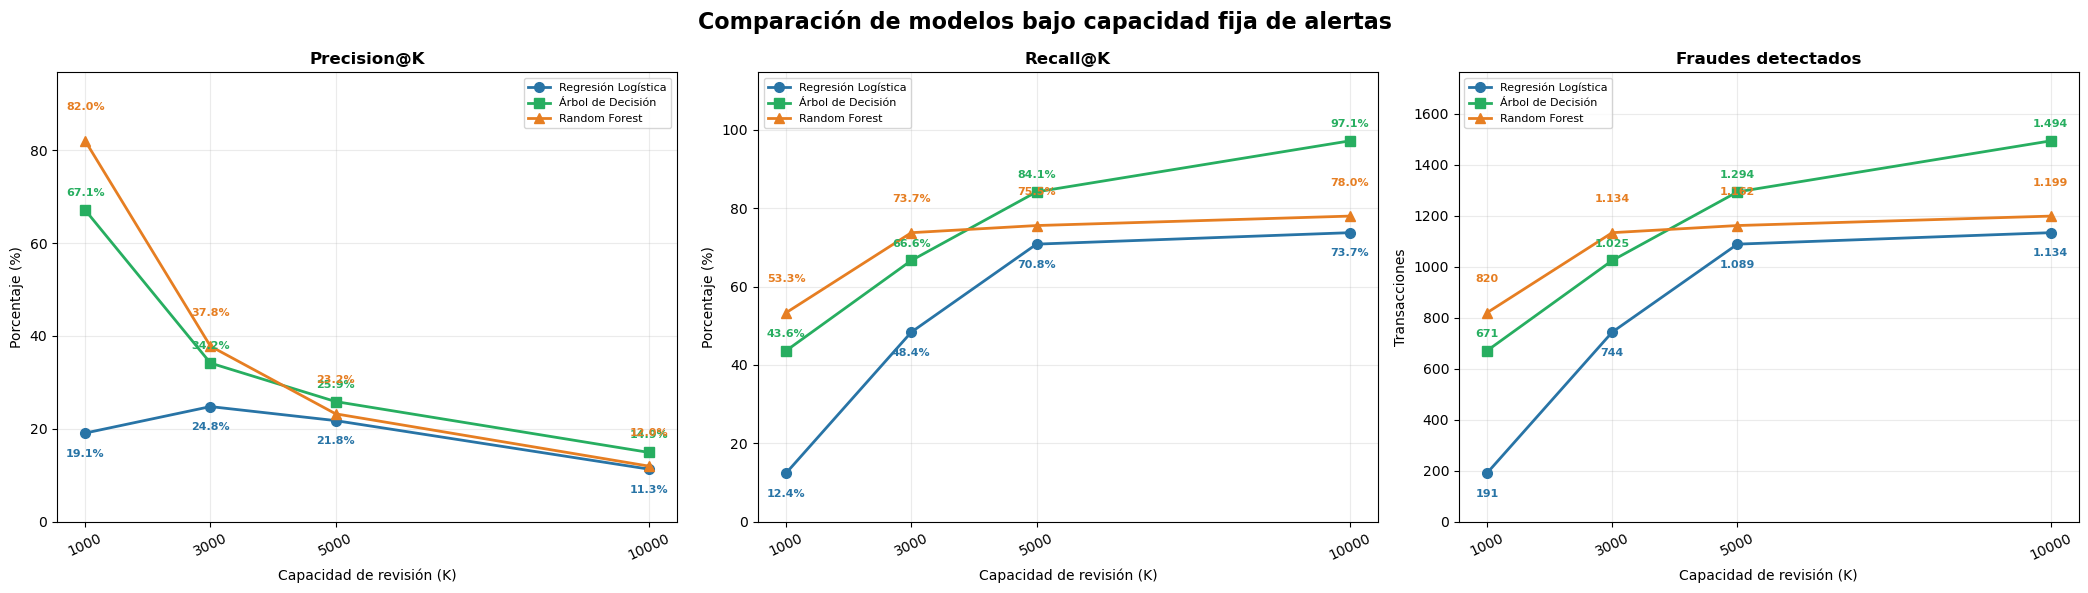

Gráfico guardado correctamente.


In [52]:

# PASO 23: Comparación gráfica de resultados Top-K

import matplotlib.pyplot as plt

# Configuración de modelos
colores = {
    "Regresión Logística": "#2874A6",
    "Árbol de Decisión": "#27AE60",
    "Random Forest": "#E67E22"
}

marcadores = {
    "Regresión Logística": "o",
    "Árbol de Decisión": "s",
    "Random Forest": "^"
}

# Crear tres gráficos
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

graficos = [
    ("Precision@K (%)", "Precision@K", "Porcentaje (%)"),
    ("Recall@K (%)", "Recall@K", "Porcentaje (%)"),
    ("Fraudes detectados", "Fraudes detectados", "Transacciones")
]

for ax, (columna, titulo, ylabel) in zip(
    axes, graficos
):

    for nombre in colores:

        datos = df_topk[
            df_topk["Modelo"] == nombre
        ].sort_values("Capacidad")

        ax.plot(
            datos["Capacidad"],
            datos[columna],
            marker=marcadores[nombre],
            linewidth=2,
            markersize=7,
            color=colores[nombre],
            label=nombre
        )

        # Agregar etiquetas
        for x, y in zip(
            datos["Capacidad"],
            datos[columna]
        ):

            etiqueta = (
                f"{y:.1f}%"
                if "(%)" in columna
                else f"{int(y):,}".replace(",", ".")
            )

            # Desplazamiento por modelo
            desplazamientos = {
                "Regresión Logística": -17,
                "Árbol de Decisión": 10,
                "Random Forest": 22
            }

            ax.annotate(
                etiqueta,
                (x, y),
                xytext=(0, desplazamientos[nombre]),
                textcoords="offset points",
                ha="center",
                fontsize=8,
                color=colores[nombre],
                fontweight="bold"
            )

    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Capacidad de revisión (K)")
    ax.set_ylabel(ylabel)
    ax.set_xticks([1000, 3000, 5000, 10000])
    ax.tick_params(axis="x", rotation=25)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

    # Ampliar el margen superior
    limite = df_topk[columna].max()
    ax.set_ylim(0, limite * 1.18)

plt.suptitle(
    "Comparación de modelos bajo capacidad fija de alertas",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "07_comparacion_topk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")




## 24. Implementación de reglas tradicionales de detección de fraude

### 24.1. Recuperación de las reglas del Midterm

En esta etapa se incorporan las tres reglas exploratorias desarrolladas durante el proyecto Midterm.

Las reglas consideran tres características transaccionales:

- **R1:** monto de la transacción.
- **R2:** monto y horario de la operación.
- **R3:** monto, horario y categoría comercial.

El objetivo consiste en evaluar el comportamiento de estas reglas sobre el mismo conjunto de validación utilizado para los modelos predictivos de Regresión Logística, Árbol de Decisión y Random Forest.

Esta evaluación permitirá comparar la capacidad de detección, la precisión y la cantidad de falsas alertas generadas por los enfoques tradicionales y los modelos de aprendizaje automático.

Las reglas se mantendrán fijas durante esta evaluación para evitar ajustes basados en los resultados del conjunto de validación.

Debe considerarse que las reglas originales surgieron de un análisis exploratorio realizado sobre el conjunto histórico integrado. Por ello, sus resultados se interpretarán inicialmente como una comparación retrospectiva, reconociendo esta limitación metodológica.


In [32]:

# PASO 24: Recuperar reglas de fraude del Midterm

# Utilizar exactamente las transacciones de validación
df_reglas = train_modelo.loc[
    X_validacion.index
].copy()

# Condición de monto
condicion_monto = df_reglas["amt"] >= 200

# Condición de horario nocturno
condicion_horario = (
    (df_reglas["hora"] >= 22) |
    (df_reglas["hora"] <= 3)
)

# Categorías comerciales del Midterm
categorias_riesgo = [
    "shopping_net",
    "misc_net",
    "grocery_pos"
]

condicion_categoria = (
    df_reglas["category"].isin(categorias_riesgo)
)

# REGLA 1: Monto
df_reglas["R1"] = (
    condicion_monto
).astype(int)

# REGLA 2: Monto + horario
df_reglas["R2"] = (
    condicion_monto &
    condicion_horario
).astype(int)

# REGLA 3: Monto + horario + categoría
df_reglas["R3"] = (
    condicion_monto &
    condicion_horario &
    condicion_categoria
).astype(int)

# Verificar cantidad de alertas
print("REGLAS DEL MIDTERM IMPLEMENTADAS")

print("\nTransacciones evaluadas:", len(df_reglas))

print("\nALERTAS GENERADAS")

for regla in ["R1", "R2", "R3"]:
    print(
        regla + ":",
        int(df_reglas[regla].sum())
    )

print("\nVERIFICACIÓN DE REGLAS")

display(
    df_reglas[
        [
            "amt",
            "hora",
            "category",
            "R1",
            "R2",
            "R3",
            "is_fraud"
        ]
    ].head(10)
)

# Comprobar alineación con el conjunto de validación
assert df_reglas.index.equals(
    X_validacion.index
), "Error: los índices no coinciden"

print("\nReglas generadas y alineadas correctamente.")


REGLAS DEL MIDTERM IMPLEMENTADAS

Transacciones evaluadas: 259335

ALERTAS GENERADAS
R1: 12394
R2: 3621
R3: 2069

VERIFICACIÓN DE REGLAS


,amt,hora,category,R1,R2,R3,is_fraud
1037340,45.16,7,grocery_pos,0,0,0,0
1037341,185.51,7,grocery_pos,0,0,0,0
1037342,122.96,7,shopping_pos,0,0,0,0
1037343,1.89,7,misc_pos,0,0,0,0
1037344,5.05,7,entertainment,0,0,0,0
1037345,13.47,7,shopping_net,0,0,0,0
1037346,72.43,7,gas_transport,0,0,0,0
1037347,111.01,7,grocery_pos,0,0,0,0
1037348,627.21,7,misc_net,1,0,0,0
1037349,56.48,7,misc_pos,0,0,0,0



Reglas generadas y alineadas correctamente.



## 25. Evaluación de las reglas tradicionales de detección de fraude

### 25.1. Evaluación de R1, R2 y R3

En esta etapa se evalúa el desempeño de las tres reglas tradicionales de detección de fraude implementadas a partir del proyecto Midterm.

Las reglas se aplican sobre las 259.335 transacciones del conjunto de validación, utilizado previamente para evaluar los modelos predictivos.

Se calcularán las siguientes métricas:

- **Accuracy:** proporción de clasificaciones correctas.
- **Precision:** porcentaje de alertas que corresponden a fraudes reales.
- **Recall:** porcentaje de fraudes reales detectados por cada regla.
- **F1-Score:** equilibrio entre Precision y Recall.
- **Falsos positivos:** transacciones legítimas que generan alertas.
- **Falsos negativos:** transacciones fraudulentas no identificadas.

El propósito es determinar la capacidad de detección de cada regla y cuantificar su impacto operativo.

Posteriormente, estos resultados se compararán con los obtenidos mediante Regresión Logística, Árbol de Decisión y Random Forest.

La comparación permitirá estudiar las diferencias entre los enfoques tradicionales basados en condiciones predefinidas y los modelos de aprendizaje automático.


In [33]:

# PASO 25: Evaluación de las reglas R1, R2 y R3

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Utilizar las etiquetas reales de validación
y_real = df_reglas["is_fraud"]

resultados_reglas = []

# Evaluar cada regla
for regla in ["R1", "R2", "R3"]:

    # Predicciones de la regla
    predicciones = df_reglas[regla]

    # Calcular matriz de confusión
    tn, fp, fn, tp = confusion_matrix(
        y_real,
        predicciones,
        labels=[0, 1]
    ).ravel()

    # Calcular métricas
    accuracy = accuracy_score(
        y_real, predicciones
    )

    precision = precision_score(
        y_real, predicciones,
        zero_division=0
    )

    recall = recall_score(
        y_real, predicciones,
        zero_division=0
    )

    f1 = f1_score(
        y_real, predicciones,
        zero_division=0
    )

    # Guardar resultados
    resultados_reglas.append({
        "Regla": regla,
        "Alertas": int(tp + fp),
        "Fraudes detectados": int(tp),
        "Fraudes no detectados": int(fn),
        "Falsos positivos": int(fp),
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2)
    })

# Crear tabla comparativa
df_resultados_reglas = pd.DataFrame(
    resultados_reglas
)

print("EVALUACIÓN DE REGLAS TRADICIONALES")

display(df_resultados_reglas)

print("\nVERIFICACIÓN GENERAL")
print("Transacciones evaluadas:", len(y_real))
print("Fraudes reales:", int(y_real.sum()))
print("Reglas evaluadas:", len(df_resultados_reglas))


EVALUACIÓN DE REGLAS TRADICIONALES


,Regla,Alertas,Fraudes detectados,Fraudes no detectados,Falsos positivos,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,R1,12394,1177,361,11217,95.54,9.50,76.53,16.90
1,R2,3621,992,546,2629,98.78,27.40,64.50,38.46
2,R3,2069,740,798,1329,99.18,35.77,48.11,41.03



VERIFICACIÓN GENERAL
Transacciones evaluadas: 259335
Fraudes reales: 1538
Reglas evaluadas: 3



## 26. Comparación de reglas tradicionales y modelos predictivos

### 26.1. Evaluación integral de seis estrategias de detección de fraude

En esta etapa se realiza una comparación entre las tres reglas tradicionales desarrolladas durante el Midterm y los tres modelos predictivos implementados mediante técnicas de Machine Learning.

Las estrategias evaluadas son:

- R1: Monto de transacción.
- R2: Monto y horario.
- R3: Monto, horario y categoría comercial.
- Regresión Logística.
- Árbol de Decisión.
- Random Forest.

La comparación utiliza el mismo conjunto de validación, conformado por 259.335 transacciones, de las cuales 1.538 corresponden a fraudes reales.

Se analizarán los siguientes indicadores:

1. Precision.
2. Recall.
3. F1-Score.
4. Fraudes detectados.
5. Falsos positivos.
6. Cantidad total de alertas generadas.

El objetivo es determinar las ventajas y limitaciones de las reglas tradicionales frente a los modelos predictivos, considerando tanto la capacidad de detección como la eficiencia operativa.

La evaluación es retrospectiva y los resultados de los modelos corresponden inicialmente al umbral de clasificación de 0.50. Por lo tanto, los resultados no constituyen todavía una selección definitiva de la estrategia operativa.


COMPARACIÓN DE SEIS ESTRATEGIAS DE FRAUDE


,Estrategia,Tipo,Precision (%),Recall (%),F1-Score (%),Fraudes detectados,Fraudes no detectados,Falsos positivos,Alertas
0,R1,Regla tradicional,9.50,76.53,16.90,1177,361,11217,12394
1,R2,Regla tradicional,27.40,64.50,38.46,992,546,2629,3621
2,R3,Regla tradicional,35.77,48.11,41.03,740,798,1329,2069
3,Regresión Logística,Machine Learning,3.59,76.14,6.85,1171,367,31463,32634
4,Árbol de Decisión,Machine Learning,13.08,97.85,23.08,1505,33,9997,11502
5,Random Forest,Machine Learning,14.56,76.27,24.45,1173,365,6884,8057


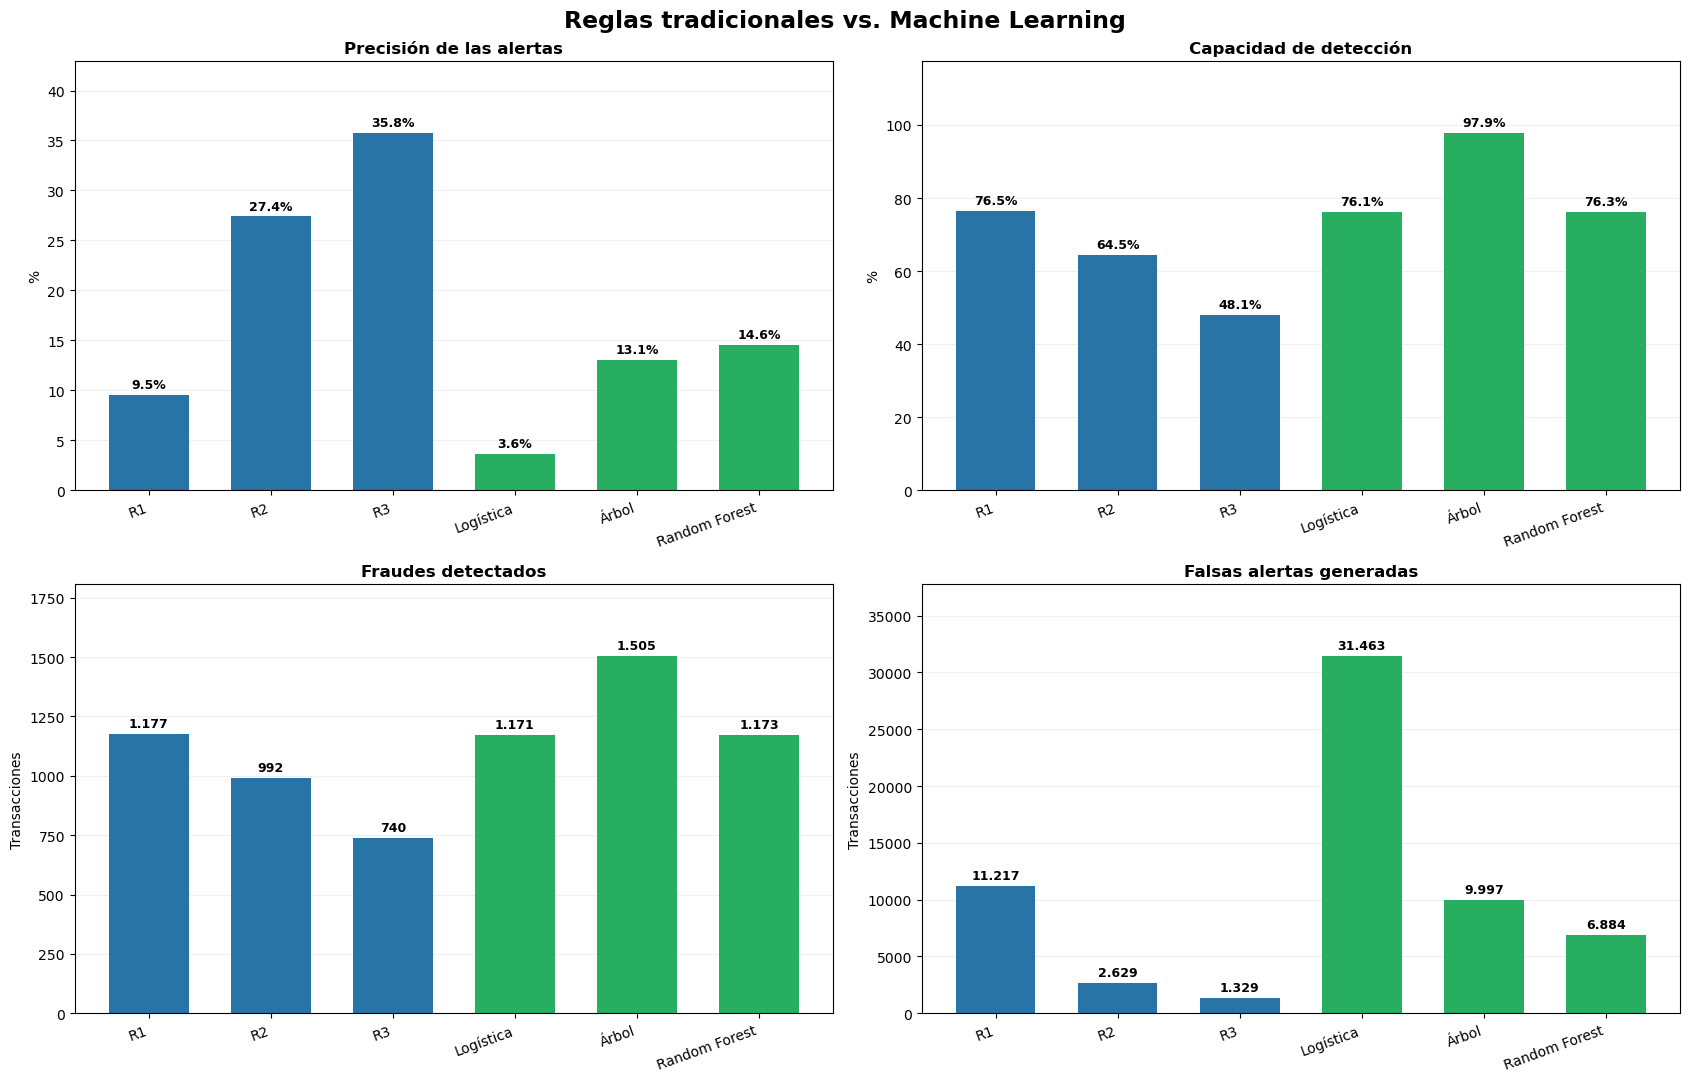

Gráfico guardado correctamente.


In [53]:

# PASO 26: Reglas tradicionales vs. Machine Learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Reunir las seis estrategias ya evaluadas
estrategias = {
    "R1": df_reglas["R1"].to_numpy(),
    "R2": df_reglas["R2"].to_numpy(),
    "R3": df_reglas["R3"].to_numpy(),
    "Regresión Logística": predicciones_logistico,
    "Árbol de Decisión": predicciones_arbol,
    "Random Forest": predicciones_rf
}

# Etiquetas reales de validación
y_real = y_validacion.to_numpy()

resultados_comparacion = []

for nombre, predicciones in estrategias.items():

    predicciones = np.asarray(predicciones)

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        predicciones,
        labels=[0, 1]
    ).ravel()

    resultados_comparacion.append({
        "Estrategia": nombre,
        "Tipo": (
            "Regla tradicional"
            if nombre in ["R1", "R2", "R3"]
            else "Machine Learning"
        ),
        "Precision (%)": precision_score(
            y_real, predicciones,
            zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_real, predicciones,
            zero_division=0
        ) * 100,
        "F1-Score (%)": f1_score(
            y_real, predicciones,
            zero_division=0
        ) * 100,
        "Fraudes detectados": int(tp),
        "Fraudes no detectados": int(fn),
        "Falsos positivos": int(fp),
        "Alertas": int(tp + fp)
    })

# Crear tabla comparativa
df_comparacion_6 = pd.DataFrame(
    resultados_comparacion
)

print("COMPARACIÓN DE SEIS ESTRATEGIAS DE FRAUDE")

display(df_comparacion_6.round(2))

# Configuración visual
colores = [
    "#2874A6", "#2874A6", "#2874A6",
    "#27AE60", "#27AE60", "#27AE60"
]

etiquetas = [
    "R1", "R2", "R3",
    "Logística", "Árbol", "Random Forest"
]

x = np.arange(len(etiquetas))

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

graficos = [
    ("Precision (%)", "Precisión de las alertas", "%"),
    ("Recall (%)", "Capacidad de detección", "%"),
    ("Fraudes detectados", "Fraudes detectados", "Transacciones"),
    ("Falsos positivos", "Falsas alertas generadas", "Transacciones")
]

for ax, (columna, titulo, ylabel) in zip(
    axes.flat, graficos
):

    barras = ax.bar(
        x,
        df_comparacion_6[columna],
        color=colores,
        width=0.65
    )

    # Agregar etiquetas numéricas
    for barra in barras:

        valor = barra.get_height()

        if "(%)" in columna:
            etiqueta = f"{valor:.1f}%"
        else:
            etiqueta = f"{int(valor):,}".replace(",", ".")

        ax.annotate(
            etiqueta,
            (
                barra.get_x() + barra.get_width() / 2,
                valor
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(titulo, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(
        etiquetas,
        rotation=20,
        ha="right"
    )

    maximo = df_comparacion_6[columna].max()
    ax.set_ylim(0, maximo * 1.20)

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle(
    "Reglas tradicionales vs. Machine Learning",
    fontsize=17,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "08_reglas_vs_machine_learning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")



## 27. Simulación de una estrategia híbrida de detección de fraude

### 27.1. Integración de reglas tradicionales y Machine Learning

En esta etapa se propone una estrategia híbrida que combina la regla tradicional R3 con el modelo predictivo Random Forest.

La estrategia consiste en priorizar inicialmente las transacciones que cumplen las condiciones de R3, ordenándolas según la puntuación de riesgo estimada por Random Forest.

Posteriormente, la capacidad disponible se completará con las transacciones restantes que presenten las mayores puntuaciones de riesgo del modelo.

Se establecerá una capacidad hipotética de revisión de 5.000 alertas durante el periodo de validación.

El desempeño de la estrategia híbrida será comparado con las 5.000 transacciones de mayor riesgo identificadas individualmente por Regresión Logística, Árbol de Decisión y Random Forest.

La evaluación considerará:

- Fraudes detectados.
- Fraudes no detectados.
- Falsas alertas.
- Precision@5000.
- Recall@5000.

Esta simulación permitirá determinar si la integración de reglas tradicionales y modelos predictivos contribuye a mejorar la priorización del fraude.

Los resultados serán exploratorios y deberán verificarse posteriormente sobre el conjunto de prueba independiente.


In [35]:

# PASO 27: Simulación de estrategia híbrida R3 + Random Forest

import numpy as np
import pandas as pd

# Capacidad hipotética de revisión
K = 5000

# Etiquetas reales
y_real = y_validacion.to_numpy()

# Puntuaciones y regla R3
riesgo_rf = np.asarray(probabilidades_rf)
riesgo_arbol = np.asarray(probabilidades_arbol)
riesgo_logistico = np.asarray(probabilidades_logistico)

regla_r3 = df_reglas["R3"].to_numpy()

# Verificar alineación
assert len(y_real) == len(riesgo_rf) == len(regla_r3)

# Crear ranking híbrido:
# Priorizar R3 y ordenar dentro de cada grupo por riesgo RF
orden_hibrido = np.lexsort((
    np.arange(len(y_real)),
    -riesgo_rf,
    -regla_r3
))

# Rankings individuales
orden_rf = np.argsort(-riesgo_rf, kind="stable")
orden_arbol = np.argsort(-riesgo_arbol, kind="stable")
orden_logistico = np.argsort(-riesgo_logistico, kind="stable")

# Estrategias
estrategias_k = {
    "Regresión Logística": orden_logistico,
    "Árbol de Decisión": orden_arbol,
    "Random Forest": orden_rf,
    "Híbrido R3 + Random Forest": orden_hibrido
}

resultados_hibridos = []

total_fraudes = int(y_real.sum())

for nombre, orden in estrategias_k.items():

    # Seleccionar las primeras 5.000 transacciones
    seleccionados = orden[:K]

    # Contar fraudes reales
    tp = int(y_real[seleccionados].sum())

    fp = K - tp
    fn = total_fraudes - tp

    resultados_hibridos.append({
        "Estrategia": nombre,
        "Alertas": K,
        "Fraudes detectados": tp,
        "Fraudes no detectados": fn,
        "Falsas alertas": fp,
        "Precision@5000 (%)": round(tp / K * 100, 2),
        "Recall@5000 (%)": round(
            tp / total_fraudes * 100, 2
        )
    })

df_hibridos = pd.DataFrame(resultados_hibridos)

print("SIMULACIÓN HÍBRIDA - CAPACIDAD DE 5.000 ALERTAS")

display(
    df_hibridos.sort_values(
        "Fraudes detectados",
        ascending=False
    ).reset_index(drop=True)
)

# Verificar composición del híbrido
seleccion_hibrida = orden_hibrido[:K]

print("\nCOMPOSICIÓN DE LA ESTRATEGIA HÍBRIDA")

print(
    "Alertas seleccionadas mediante prioridad R3:",
    int(regla_r3[seleccion_hibrida].sum())
)

print(
    "Alertas restantes priorizadas por Random Forest:",
    int((regla_r3[seleccion_hibrida] == 0).sum())
)

print("\nSimulación completada correctamente.")


SIMULACIÓN HÍBRIDA - CAPACIDAD DE 5.000 ALERTAS


,Estrategia,Alertas,Fraudes detectados,Fraudes no detectados,Falsas alertas,Precision@5000 (%),Recall@5000 (%)
0,Árbol de Decisión,5000,1294,244,3706,25.88,84.14
1,Random Forest,5000,1162,376,3838,23.24,75.55
2,Híbrido R3 + Random Forest,5000,1158,380,3842,23.16,75.29
3,Regresión Logística,5000,1089,449,3911,21.78,70.81



COMPOSICIÓN DE LA ESTRATEGIA HÍBRIDA
Alertas seleccionadas mediante prioridad R3: 2069
Alertas restantes priorizadas por Random Forest: 2931

Simulación completada correctamente.



## 28. Preparación de la evaluación final

### 28.1. Definición de estrategias y umbrales

Una vez concluidas las etapas de entrenamiento, validación y simulación operativa, se establecen las configuraciones que serán utilizadas para evaluar el desempeño de las estrategias de detección de fraude sobre el conjunto de prueba independiente.

Se evaluarán las tres reglas tradicionales y los tres modelos predictivos.

Para los modelos de Machine Learning se utilizarán los siguientes umbrales:

- Regresión Logística: 0.80.
- Árbol de Decisión: 0.90.
- Random Forest: 0.70.

Las reglas tradicionales mantendrán las mismas condiciones aplicadas durante la validación.

Estos parámetros se fijan antes de consultar los resultados del conjunto de prueba y no serán modificados posteriormente con base en su desempeño.

El objetivo es evaluar la capacidad de generalización de las estrategias en transacciones posteriores, identificando posibles diferencias respecto a los resultados de validación.


In [36]:

# PASO 28: Fijar configuraciones para evaluación final

# Umbrales seleccionados durante la validación
umbrales_finales = {
    "Regresión Logística": 0.80,
    "Árbol de Decisión": 0.90,
    "Random Forest": 0.70
}

# Reglas tradicionales
configuracion_reglas = {
    "R1": "Monto >= 200",
    "R2": "Monto >= 200 y horario 22:00 a 03:59",
    "R3": (
        "Monto >= 200, horario 22:00 a 03:59 "
        "y categorías shopping_net, misc_net, grocery_pos"
    )
}

print("CONFIGURACIÓN DE EVALUACIÓN FINAL")

print("\nMODELOS PREDICTIVOS")
for modelo, umbral in umbrales_finales.items():
    print(f"{modelo}: umbral {umbral:.2f}")

print("\nREGLAS TRADICIONALES")
for regla, descripcion in configuracion_reglas.items():
    print(f"{regla}: {descripcion}")

print("\nCONJUNTO DE PRUEBA")
print("Transacciones:", len(X_test))
print("Variables predictivas:", X_test.shape[1])

print("\nConfiguración fijada correctamente.")
print("No se han generado predicciones sobre prueba.")


CONFIGURACIÓN DE EVALUACIÓN FINAL

MODELOS PREDICTIVOS
Regresión Logística: umbral 0.80
Árbol de Decisión: umbral 0.90
Random Forest: umbral 0.70

REGLAS TRADICIONALES
R1: Monto >= 200
R2: Monto >= 200 y horario 22:00 a 03:59
R3: Monto >= 200, horario 22:00 a 03:59 y categorías shopping_net, misc_net, grocery_pos

CONJUNTO DE PRUEBA
Transacciones: 555719
Variables predictivas: 8

Configuración fijada correctamente.
No se han generado predicciones sobre prueba.



## 29. Evaluación final sobre el conjunto de prueba

### 29.1. Evaluación independiente de las seis estrategias

En esta etapa se evaluará el desempeño de las tres reglas tradicionales y los tres modelos predictivos utilizando el conjunto de prueba independiente, compuesto por 555.719 transacciones.

Este conjunto corresponde a un periodo posterior al utilizado durante el entrenamiento y la validación.

Las estrategias evaluadas serán:

- R1: monto de transacción.
- R2: monto y horario.
- R3: monto, horario y categoría comercial.
- Regresión Logística: umbral 0.80.
- Árbol de Decisión: umbral 0.90.
- Random Forest: umbral 0.70.

Se calcularán Precision, Recall, F1-Score, fraudes detectados, fraudes no detectados, falsas alertas y total de alertas.

El propósito es comprobar la capacidad de generalización de las estrategias y analizar si los resultados de validación se mantienen en transacciones posteriores.

Los umbrales permanecerán fijos y no serán modificados en función de los resultados de prueba.

La evaluación de las reglas tradicionales conserva una limitación metodológica: sus condiciones se derivaron originalmente de un análisis exploratorio que incluyó datos históricos posteriormente destinados a prueba. Por tanto, sus resultados deben interpretarse como retrospectivos y no como una validación completamente independiente del diseño de las reglas.


In [37]:

# PASO 29: Evaluación final de las seis estrategias

import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# ========================================
# 1. PREPARAR LAS REGLAS TRADICIONALES
# ========================================

df_reglas_test = test_modelo.copy()

# Condiciones originales
monto_test = df_reglas_test["amt"] >= 200

horario_test = (
    (df_reglas_test["hora"] >= 22) |
    (df_reglas_test["hora"] <= 3)
)

categoria_test = df_reglas_test["category"].isin(
    categorias_riesgo
)

# Aplicar las tres reglas
df_reglas_test["R1"] = monto_test.astype(int)

df_reglas_test["R2"] = (
    monto_test & horario_test
).astype(int)

df_reglas_test["R3"] = (
    monto_test & horario_test & categoria_test
).astype(int)

# ========================================
# 2. GENERAR PREDICCIONES DE LOS MODELOS
# ========================================

print("GENERANDO PREDICCIONES SOBRE PRUEBA")

prob_test_logistico = modelo_logistico.predict_proba(
    X_test
)[:, 1]

prob_test_arbol = modelo_arbol.predict_proba(
    X_test
)[:, 1]

prob_test_rf = modelo_random_forest.predict_proba(
    X_test
)[:, 1]

# Aplicar los umbrales fijados en el PASO 28
pred_test_logistico = (
    prob_test_logistico >=
    umbrales_finales["Regresión Logística"]
).astype(int)

pred_test_arbol = (
    prob_test_arbol >=
    umbrales_finales["Árbol de Decisión"]
).astype(int)

pred_test_rf = (
    prob_test_rf >=
    umbrales_finales["Random Forest"]
).astype(int)

# ========================================
# 3. REUNIR LAS SEIS ESTRATEGIAS
# ========================================

estrategias_test = {
    "R1": df_reglas_test["R1"].to_numpy(),
    "R2": df_reglas_test["R2"].to_numpy(),
    "R3": df_reglas_test["R3"].to_numpy(),
    "Regresión Logística": pred_test_logistico,
    "Árbol de Decisión": pred_test_arbol,
    "Random Forest": pred_test_rf
}

# Comprobar que las etiquetas estén alineadas
assert df_reglas_test.index.equals(X_test.index)
assert y_test.index.equals(X_test.index)

y_real_test = y_test.to_numpy()

# ========================================
# 4. EVALUAR LAS ESTRATEGIAS
# ========================================

resultados_test = []

for nombre, predicciones in estrategias_test.items():

    tn, fp, fn, tp = confusion_matrix(
        y_real_test,
        predicciones,
        labels=[0, 1]
    ).ravel()

    resultados_test.append({
        "Estrategia": nombre,
        "Alertas": int(tp + fp),
        "Fraudes detectados": int(tp),
        "Fraudes no detectados": int(fn),
        "Falsos positivos": int(fp),
        "Precision (%)": round(
            precision_score(
                y_real_test,
                predicciones,
                zero_division=0
            ) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(
                y_real_test,
                predicciones,
                zero_division=0
            ) * 100, 2
        ),
        "F1-Score (%)": round(
            f1_score(
                y_real_test,
                predicciones,
                zero_division=0
            ) * 100, 2
        )
    })

# ========================================
# 5. MOSTRAR RESULTADOS
# ========================================

df_resultados_test = pd.DataFrame(
    resultados_test
)

print("\nEVALUACIÓN FINAL - SEIS ESTRATEGIAS")

display(df_resultados_test)

print("\nVERIFICACIÓN GENERAL")
print("Transacciones evaluadas:", len(y_real_test))
print("Fraudes reales:", int(y_real_test.sum()))
print("Estrategias evaluadas:", len(df_resultados_test))

print("\nEvaluación final completada.")


GENERANDO PREDICCIONES SOBRE PRUEBA

EVALUACIÓN FINAL - SEIS ESTRATEGIAS


,Estrategia,Alertas,Fraudes detectados,Fraudes no detectados,Falsos positivos,Precision (%),Recall (%),F1-Score (%)
0,R1,25353,1611,534,23742,6.35,75.10,11.72
1,R2,7035,1363,782,5672,19.37,63.54,29.69
2,R3,3898,1069,1076,2829,27.42,49.84,35.38
3,Regresión Logística,8252,1395,750,6857,16.90,65.03,26.83
4,Árbol de Decisión,13254,2001,144,11253,15.10,93.29,25.99
5,Random Forest,2077,1275,870,802,61.39,59.44,60.40



VERIFICACIÓN GENERAL
Transacciones evaluadas: 555719
Fraudes reales: 2145
Estrategias evaluadas: 6

Evaluación final completada.



## 30. Comparación de resultados entre validación y prueba

### 30.1. Análisis de estabilidad y generalización

En esta etapa se comparará el desempeño de las seis estrategias de detección de fraude entre los conjuntos de validación y prueba.

Para garantizar una comparación metodológicamente consistente, se utilizarán los mismos umbrales de clasificación fijados antes de la evaluación final:

- Regresión Logística: 0.80.
- Árbol de Decisión: 0.90.
- Random Forest: 0.70.

Las reglas R1, R2 y R3 mantendrán sus condiciones originales.

Se analizarán Precision, Recall y F1-Score, así como las variaciones observadas entre ambos periodos.

El objetivo consiste en identificar posibles cambios en el comportamiento predictivo y determinar qué estrategias presentan una mayor estabilidad.

Debe considerarse que los conjuntos de validación y prueba tienen tamaños y tasas de fraude diferentes. Por ello, la comparación priorizará métricas porcentuales y no únicamente cantidades absolutas de alertas o fraudes detectados.


COMPARACIÓN VALIDACIÓN VS PRUEBA


,Estrategia,Precision_validacion,Recall_validacion,F1_validacion,Precision_prueba,Recall_prueba,F1_prueba,Delta_Precision,Delta_Recall,Delta_F1
0,R1,9.50,76.53,16.90,6.35,75.10,11.72,-3.15,-1.43,-5.18
1,R2,27.40,64.50,38.46,19.37,63.54,29.69,-8.03,-0.96,-8.77
2,R3,35.77,48.11,41.03,27.42,49.84,35.38,-8.35,1.73,-5.65
3,Regresión Logística,24.13,66.12,35.36,16.90,65.03,26.83,-7.23,-1.09,-8.53
4,Árbol de Decisión,21.69,94.93,35.31,15.10,93.29,25.99,-6.59,-1.64,-9.32
5,Random Forest,71.02,61.51,65.92,61.39,59.44,60.40,-9.63,-2.07,-5.52


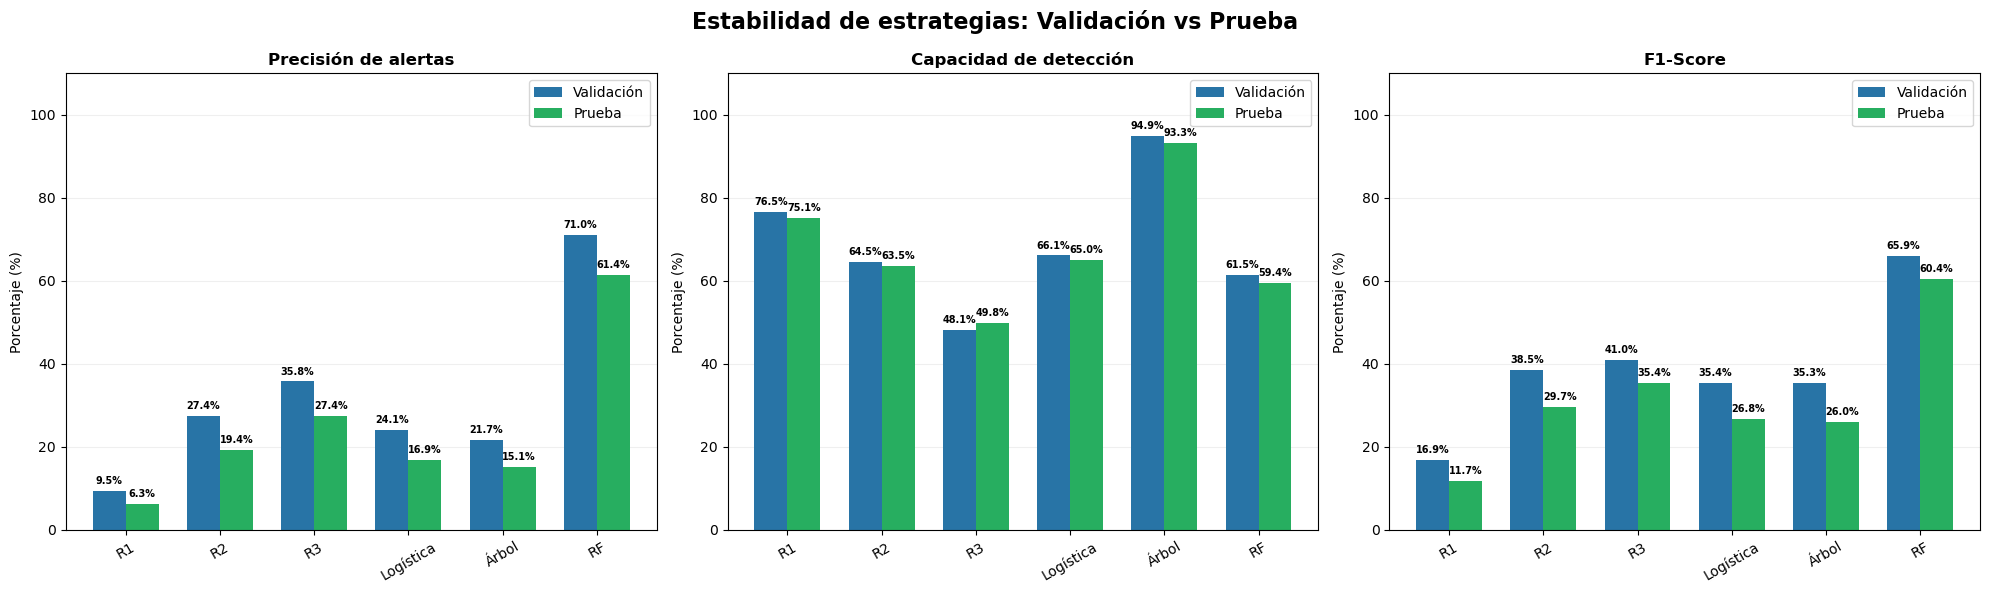

Gráfico guardado correctamente.


In [54]:

# PASO 30: Comparación entre validación y prueba

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Aplicar a validación los umbrales fijados
estrategias_validacion = {
    "R1": df_reglas["R1"].to_numpy(),
    "R2": df_reglas["R2"].to_numpy(),
    "R3": df_reglas["R3"].to_numpy(),
    "Regresión Logística": (
        probabilidades_logistico >= 0.80
    ).astype(int),
    "Árbol de Decisión": (
        probabilidades_arbol >= 0.90
    ).astype(int),
    "Random Forest": (
        probabilidades_rf >= 0.70
    ).astype(int)
}

# Calcular métricas con las mismas configuraciones
resultados_validacion = []

for nombre, predicciones in estrategias_validacion.items():

    resultados_validacion.append({
        "Estrategia": nombre,
        "Precision_validacion": precision_score(
            y_validacion, predicciones,
            zero_division=0
        ) * 100,
        "Recall_validacion": recall_score(
            y_validacion, predicciones,
            zero_division=0
        ) * 100,
        "F1_validacion": f1_score(
            y_validacion, predicciones,
            zero_division=0
        ) * 100
    })

df_validacion_final = pd.DataFrame(
    resultados_validacion
)

# Preparar los resultados de prueba
df_prueba_final = df_resultados_test[
    [
        "Estrategia",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
].rename(columns={
    "Precision (%)": "Precision_prueba",
    "Recall (%)": "Recall_prueba",
    "F1-Score (%)": "F1_prueba"
})

# Unir los resultados
df_estabilidad = pd.merge(
    df_validacion_final,
    df_prueba_final,
    on="Estrategia"
)

# Calcular diferencias en puntos porcentuales
for metrica in ["Precision", "Recall", "F1"]:

    df_estabilidad[f"Delta_{metrica}"] = (
        df_estabilidad[f"{metrica}_prueba"] -
        df_estabilidad[f"{metrica}_validacion"]
    )

print("COMPARACIÓN VALIDACIÓN VS PRUEBA")

display(df_estabilidad.round(2))

# ========================================
# GRÁFICOS COMPARATIVOS
# ========================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

metricas = [
    ("Precision", "Precisión de alertas"),
    ("Recall", "Capacidad de detección"),
    ("F1", "F1-Score")
]

x = np.arange(len(df_estabilidad))
ancho = 0.35

for ax, (metrica, titulo) in zip(axes, metricas):

    barras_val = ax.bar(
        x - ancho/2,
        df_estabilidad[f"{metrica}_validacion"],
        width=ancho,
        label="Validación",
        color="#2874A6"
    )

    barras_test = ax.bar(
        x + ancho/2,
        df_estabilidad[f"{metrica}_prueba"],
        width=ancho,
        label="Prueba",
        color="#27AE60"
    )

    for barras in [barras_val, barras_test]:
        for barra in barras:

            altura = barra.get_height()

            ax.annotate(
                f"{altura:.1f}%",
                (
                    barra.get_x() + barra.get_width()/2,
                    altura
                ),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                fontsize=7,
                fontweight="bold"
            )

    ax.set_title(titulo, fontweight="bold")
    ax.set_ylabel("Porcentaje (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(
        ["R1", "R2", "R3", "Logística", "Árbol", "RF"],
        rotation=30
    )
    ax.set_ylim(0, 110)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle(
    "Estabilidad de estrategias: Validación vs Prueba",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "09_validacion_vs_prueba.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")




## 31. Análisis de eficiencia operativa de las estrategias

En esta etapa se analizará la eficiencia operativa de las seis estrategias de detección de fraude evaluadas sobre el conjunto de prueba.

Además de las métricas predictivas tradicionales, se incorporarán indicadores relacionados con la carga de trabajo que podría generar cada estrategia en un sistema de monitoreo transaccional.

Los indicadores serán:

1. **Alertas por fraude detectado:** cantidad promedio de alertas generadas por cada fraude identificado.
2. **Alertas por cada 1.000 transacciones:** frecuencia relativa de alertas en el volumen transaccional.
3. **Falsas alertas por fraude detectado:** número de alertas incorrectas por cada fraude identificado.

El propósito es analizar las implicaciones operativas de cada estrategia y determinar cuáles podrían contribuir a una utilización más eficiente de los recursos destinados a la revisión de operaciones sospechosas.

Este análisis se basa en una simulación retrospectiva y no incorpora todavía costos monetarios reales, tiempos de revisión ni comportamiento de clientes.


EFICIENCIA OPERATIVA DE LAS ESTRATEGIAS


,Estrategia,Alertas,Fraudes detectados,Alertas por fraude,Alertas por 1000 transacciones,Falsas alertas por fraude
0,R1,25353,1611,15.74,45.62,14.74
1,R2,7035,1363,5.16,12.66,4.16
2,R3,3898,1069,3.65,7.01,2.65
3,Regresión Logística,8252,1395,5.92,14.85,4.92
4,Árbol de Decisión,13254,2001,6.62,23.85,5.62
5,Random Forest,2077,1275,1.63,3.74,0.63


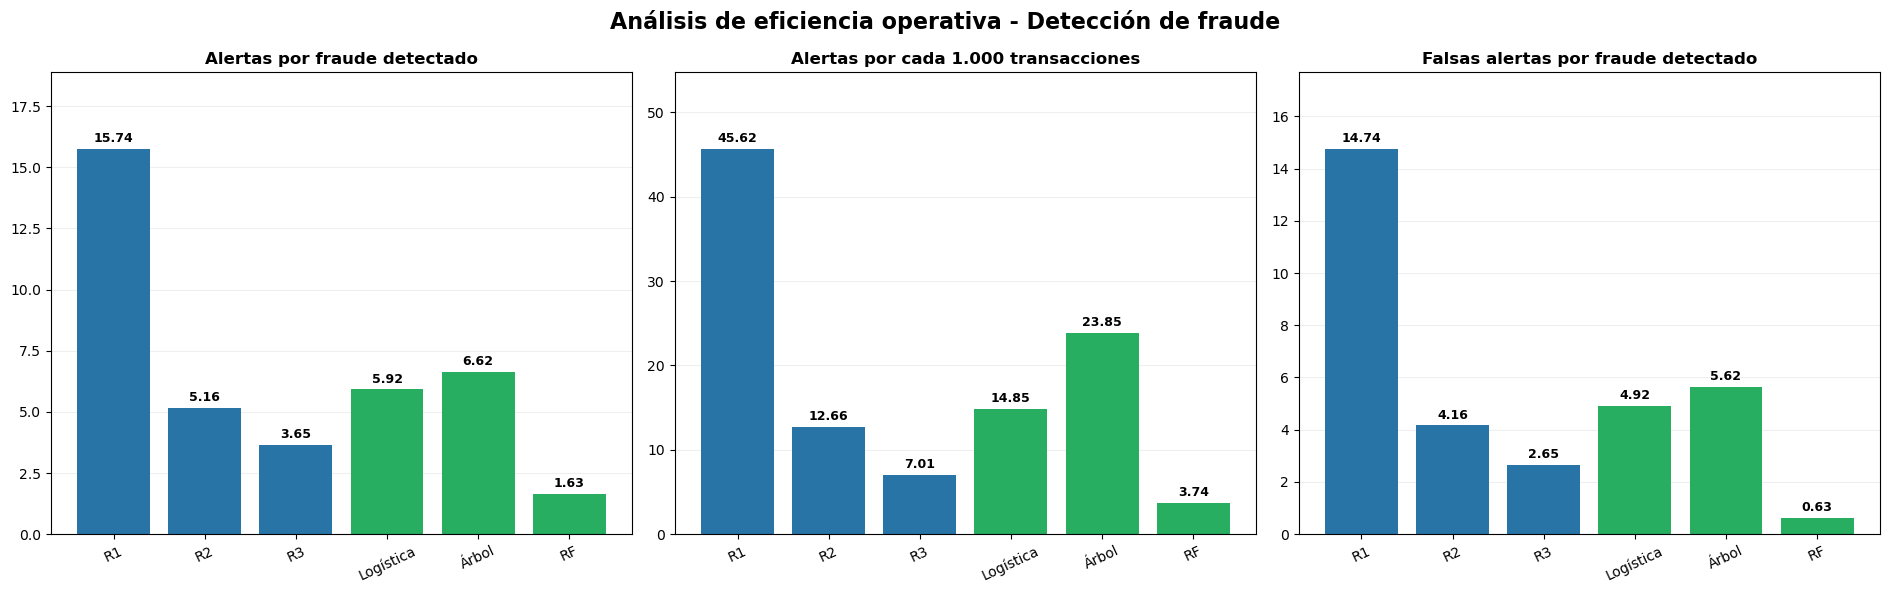

Gráfico guardado correctamente.


In [55]:

# PASO 31: Análisis de eficiencia operativa

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Utilizar resultados de prueba
df_eficiencia = df_resultados_test.copy()

total_transacciones = len(y_test)

# Calcular indicadores operativos
df_eficiencia["Alertas por fraude"] = (
    df_eficiencia["Alertas"] /
    df_eficiencia["Fraudes detectados"].replace(0, np.nan)
)

df_eficiencia["Alertas por 1000 transacciones"] = (
    df_eficiencia["Alertas"] /
    total_transacciones * 1000
)

df_eficiencia["Falsas alertas por fraude"] = (
    df_eficiencia["Falsos positivos"] /
    df_eficiencia["Fraudes detectados"].replace(0, np.nan)
)

columnas = [
    "Estrategia",
    "Alertas",
    "Fraudes detectados",
    "Alertas por fraude",
    "Alertas por 1000 transacciones",
    "Falsas alertas por fraude"
]

print("EFICIENCIA OPERATIVA DE LAS ESTRATEGIAS")

display(
    df_eficiencia[columnas].round(2)
)

# Crear gráficos
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

indicadores = [
    ("Alertas por fraude", "Alertas por fraude detectado"),
    (
        "Alertas por 1000 transacciones",
        "Alertas por cada 1.000 transacciones"
    ),
    (
        "Falsas alertas por fraude",
        "Falsas alertas por fraude detectado"
    )
]

etiquetas = [
    "R1", "R2", "R3",
    "Logística", "Árbol", "RF"
]

colores = [
    "#2874A6", "#2874A6", "#2874A6",
    "#27AE60", "#27AE60", "#27AE60"
]

for ax, (columna, titulo) in zip(
    axes, indicadores
):

    barras = ax.bar(
        etiquetas,
        df_eficiencia[columna],
        color=colores
    )

    for barra in barras:

        valor = barra.get_height()

        ax.annotate(
            f"{valor:.2f}",
            (
                barra.get_x() + barra.get_width()/2,
                valor
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(titulo, fontweight="bold")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(
        0,
        df_eficiencia[columna].max() * 1.2
    )
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle(
    "Análisis de eficiencia operativa - Detección de fraude",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "10_eficiencia_operativa.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")




## 32. Simulación económica de estrategias de detección de fraude

### 32.1. Estimación de costos operativos y pérdidas potenciales

En esta etapa se desarrolla una simulación económica para comparar las seis estrategias de detección de fraude desde una perspectiva de eficiencia financiera.

Se consideran dos componentes:

1. **Costo operativo de revisión:** asociado a la cantidad de alertas que deben ser analizadas.
2. **Pérdida potencial por fraude no detectado:** asociada a las transacciones fraudulentas que no fueron identificadas por cada estrategia.

Se plantea la siguiente fórmula:

Costo total estimado = (Alertas × Costo por revisión) + (Fraudes no detectados × Pérdida promedio por fraude)

Como escenario inicial se utilizarán los siguientes supuestos hipotéticos:

- Costo por revisión de alerta: USD 2.
- Pérdida promedio por fraude no detectado: USD 100.

Estos valores son referenciales y no representan costos reales de una entidad financiera.

El propósito consiste en comparar el impacto económico potencial de las estrategias y analizar cómo la valoración de los costos puede modificar la selección del modelo más conveniente.

La simulación supone que todas las alertas son revisadas y que los fraudes identificados pueden ser gestionados oportunamente. No considera costos adicionales, recuperaciones, interrupciones del servicio ni efectos sobre los clientes.


SUPUESTOS ECONÓMICOS
Costo por revisión: USD 2.00
Pérdida por fraude no detectado: USD 100.00

COMPARACIÓN ECONÓMICA DE ESTRATEGIAS


,Estrategia,Alertas,Fraudes detectados,Fraudes no detectados,Costo revisión,Pérdida no detectada,Costo total estimado
0,Árbol de Decisión,13254,2001,144,26508.0,14400.0,40908.0
1,Random Forest,2077,1275,870,4154.0,87000.0,91154.0
2,Regresión Logística,8252,1395,750,16504.0,75000.0,91504.0
3,R2,7035,1363,782,14070.0,78200.0,92270.0
4,R1,25353,1611,534,50706.0,53400.0,104106.0
5,R3,3898,1069,1076,7796.0,107600.0,115396.0


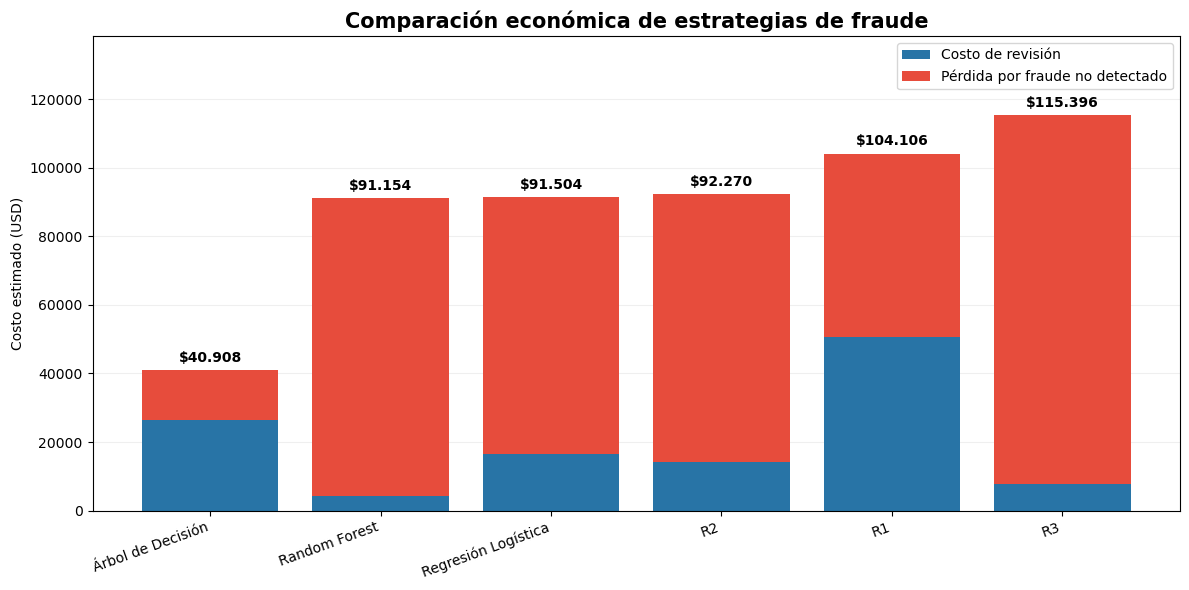

Gráfico guardado correctamente.


In [56]:

# PASO 32: Simulación económica de las seis estrategias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================
# 1. SUPUESTOS ECONÓMICOS
# =====================================

costo_revision = 2.00
perdida_por_fraude = 100.00

print("SUPUESTOS ECONÓMICOS")

print(f"Costo por revisión: USD {costo_revision:.2f}")
print(f"Pérdida por fraude no detectado: USD {perdida_por_fraude:.2f}")

# =====================================
# 2. CALCULAR COSTOS
# =====================================

df_costos = df_resultados_test.copy()

# Costo de revisar todas las alertas
df_costos["Costo revisión"] = (
    df_costos["Alertas"] * costo_revision
)

# Pérdidas estimadas por fraudes no detectados
df_costos["Pérdida no detectada"] = (
    df_costos["Fraudes no detectados"] *
    perdida_por_fraude
)

# Costo económico total
df_costos["Costo total estimado"] = (
    df_costos["Costo revisión"] +
    df_costos["Pérdida no detectada"]
)

# Ordenar del menor al mayor costo
df_costos = df_costos.sort_values(
    "Costo total estimado"
).reset_index(drop=True)

columnas = [
    "Estrategia",
    "Alertas",
    "Fraudes detectados",
    "Fraudes no detectados",
    "Costo revisión",
    "Pérdida no detectada",
    "Costo total estimado"
]

print("\nCOMPARACIÓN ECONÓMICA DE ESTRATEGIAS")

display(
    df_costos[columnas].round(2)
)

# =====================================
# 3. GRÁFICO COMPARATIVO
# =====================================

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(df_costos))

costo_operativo = df_costos["Costo revisión"]
perdida = df_costos["Pérdida no detectada"]
total = df_costos["Costo total estimado"]

ax.bar(
    x,
    costo_operativo,
    label="Costo de revisión",
    color="#2874A6"
)

ax.bar(
    x,
    perdida,
    bottom=costo_operativo,
    label="Pérdida por fraude no detectado",
    color="#E74C3C"
)

# Etiquetas del costo total
for i, valor in enumerate(total):

    ax.annotate(
        f"${valor:,.0f}".replace(",", "."),
        (i, valor),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Comparación económica de estrategias de fraude",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Costo estimado (USD)")
ax.set_xticks(x)
ax.set_xticklabels(
    df_costos["Estrategia"],
    rotation=20,
    ha="right"
)

ax.set_ylim(0, total.max() * 1.20)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "11_costos_estrategias.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")



## 33. Análisis de sensibilidad económica

### 33.1. Evaluación de múltiples escenarios de costos

En esta etapa se desarrolla un análisis de sensibilidad económica para determinar cómo cambia la conveniencia de las estrategias de detección de fraude ante variaciones en los costos operativos y las pérdidas potenciales.

Se consideran cinco escenarios de costo por revisión de alerta:

- USD 1.
- USD 2.
- USD 5.
- USD 10.
- USD 20.

Asimismo, se consideran cinco escenarios de pérdida promedio por fraude no detectado:

- USD 25.
- USD 50.
- USD 100.
- USD 250.
- USD 500.

La combinación de ambos factores genera 25 escenarios económicos.

Para cada escenario se calculará el costo total estimado de las seis estrategias evaluadas.

Se identificará la alternativa de menor costo bajo cada combinación, permitiendo determinar si la selección del modelo depende de las condiciones económicas consideradas.

Los valores son hipotéticos y se utilizan únicamente con fines académicos. Los resultados no representan ahorros reales ni pérdidas observadas de una institución financiera.


ESTRATEGIA DE MENOR COSTO EN CADA ESCENARIO


Pérdida fraude,25,50,100,250,500
Costo revisión,,,,,
1,Árbol de Decisión,Árbol de Decisión,Árbol de Decisión,Árbol de Decisión,Árbol de Decisión
2,Random Forest,Árbol de Decisión,Árbol de Decisión,Árbol de Decisión,Árbol de Decisión
5,Random Forest,Random Forest,Árbol de Decisión,Árbol de Decisión,Árbol de Decisión
10,Random Forest,Random Forest,Random Forest,Árbol de Decisión,Árbol de Decisión
20,Random Forest,Random Forest,Random Forest,Random Forest,Árbol de Decisión



RESUMEN DE ESCENARIOS


,Estrategia,Escenarios de menor costo
0,Árbol de Decisión,15
1,Random Forest,10


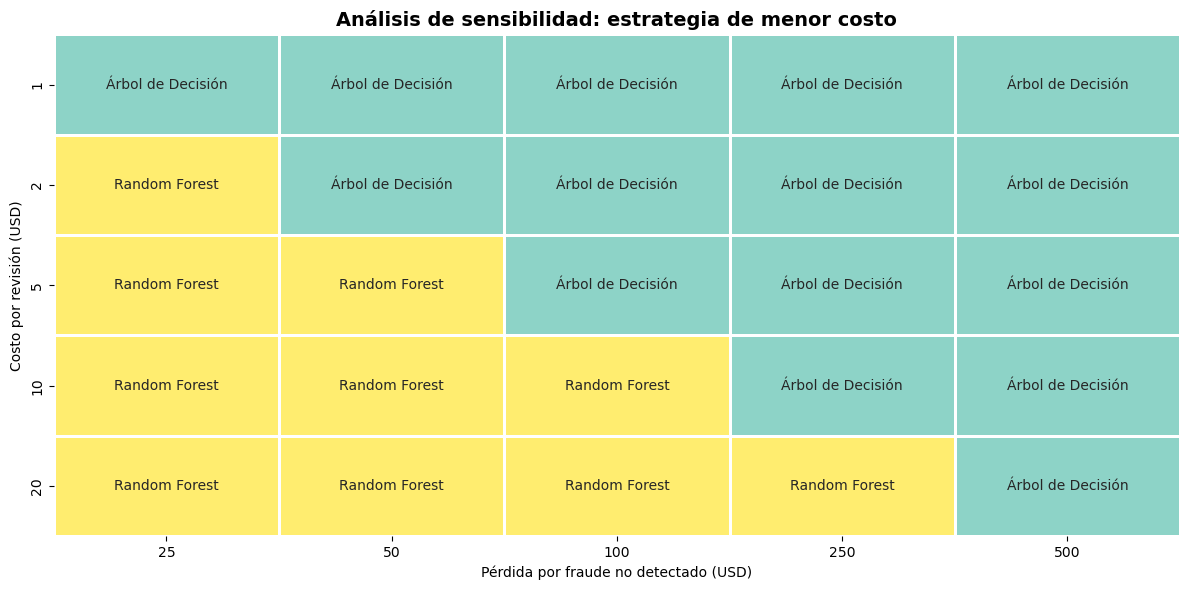

Gráfico guardado correctamente.


In [57]:

# PASO 33: Análisis de sensibilidad económica

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Escenarios hipotéticos
costos_revision = [1, 2, 5, 10, 20]
perdidas_fraude = [25, 50, 100, 250, 500]

resultados_sensibilidad = []

# Evaluar todas las combinaciones
for costo in costos_revision:

    for perdida in perdidas_fraude:

        for _, fila in df_resultados_test.iterrows():

            costo_total = (
                fila["Alertas"] * costo +
                fila["Fraudes no detectados"] * perdida
            )

            resultados_sensibilidad.append({
                "Costo revisión": costo,
                "Pérdida fraude": perdida,
                "Estrategia": fila["Estrategia"],
                "Costo total": costo_total
            })

# Crear DataFrame
df_sensibilidad = pd.DataFrame(
    resultados_sensibilidad
)

# Seleccionar menor costo en cada escenario
indices_mejores = df_sensibilidad.groupby(
    ["Costo revisión", "Pérdida fraude"]
)["Costo total"].idxmin()

df_mejores = df_sensibilidad.loc[
    indices_mejores
].copy()

# Crear matriz de estrategias ganadoras
matriz_ganadores = df_mejores.pivot(
    index="Costo revisión",
    columns="Pérdida fraude",
    values="Estrategia"
)

print("ESTRATEGIA DE MENOR COSTO EN CADA ESCENARIO")

display(matriz_ganadores)

# Contar escenarios ganados por estrategia
conteo_ganadores = (
    df_mejores["Estrategia"]
    .value_counts()
    .reset_index()
)

conteo_ganadores.columns = [
    "Estrategia",
    "Escenarios de menor costo"
]

print("\nRESUMEN DE ESCENARIOS")

display(conteo_ganadores)

# ======================================
# VISUALIZACIÓN DE LA SENSIBILIDAD
# ======================================

# Asignar códigos numéricos a estrategias
estrategias = list(
    df_resultados_test["Estrategia"]
)

mapa_codigos = {
    nombre: i for i, nombre in enumerate(estrategias)
}


# Convertir estrategias a códigos numéricos
# sin generar advertencias de Pandas

matriz_numerica = matriz_ganadores.apply(
    lambda columna: columna.map(mapa_codigos)
).astype(int)


fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    matriz_numerica,
    annot=matriz_ganadores,
    fmt="",
    cmap="Set3",
    linewidths=1,
    cbar=False,
    ax=ax
)

ax.set_title(
    "Análisis de sensibilidad: estrategia de menor costo",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Pérdida por fraude no detectado (USD)")
ax.set_ylabel("Costo por revisión (USD)")


plt.tight_layout()

# Guardar gráfico en formato PNG
plt.savefig(
    carpeta_graficos / "12_sensibilidad_economica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado correctamente.")



## 34. Conclusiones y recomendaciones

### 34.1. Conclusiones

El proyecto permitió desarrollar y evaluar un sistema experimental de detección de fraude en transacciones electrónicas, mediante la comparación de reglas tradicionales y modelos predictivos de Machine Learning.

A partir del análisis de 1.852.394 transacciones, se implementaron tres modelos supervisados: Regresión Logística, Árbol de Decisión y Random Forest. Posteriormente, sus resultados se compararon con las tres reglas de detección R1, R2 y R3, desarrolladas durante el Midterm.

**Primera conclusión: capacidad de detección.**

El Árbol de Decisión obtuvo el mayor Recall en el conjunto de prueba, identificando 2.001 de los 2.145 fraudes reales, equivalente al 93,29 %. Sin embargo, generó 11.253 falsas alertas, evidenciando un compromiso entre la capacidad de detección y la carga operativa.

**Segunda conclusión: precisión de las alertas.**

Random Forest alcanzó una precisión del 61,39 % con el umbral seleccionado de 0,70. De las 2.077 alertas generadas, 1.275 correspondieron a fraudes reales y 802 a transacciones legítimas.

Este resultado demuestra su potencial para priorizar transacciones de mayor riesgo cuando la capacidad de revisión es limitada.

**Tercera conclusión: reglas tradicionales frente a Machine Learning.**

Las reglas R1, R2 y R3 demostraron que el aumento de condiciones puede reducir la cantidad de falsas alertas y mejorar la precisión, aunque también puede disminuir el porcentaje de fraudes detectados.

Los modelos predictivos permitieron incorporar patrones aprendidos a partir de los datos, ofreciendo alternativas para mejorar la detección y priorización de transacciones sospechosas.

**Cuarta conclusión: evaluación operativa.**

La simulación Top-K evidenció que Random Forest obtuvo mejores resultados con capacidades de revisión de 1.000 y 3.000 alertas, mientras que el Árbol de Decisión fue superior con capacidades de 5.000 y 10.000 alertas, dentro del conjunto de validación.

Esto demuestra que la selección del modelo depende también de las restricciones operativas.

**Quinta conclusión: evaluación económica.**

Bajo el escenario hipotético de USD 2 por revisión y USD 100 por fraude no detectado, el Árbol de Decisión presentó el menor costo estimado, con USD 40.908.

El análisis de sensibilidad mostró que el Árbol de Decisión obtuvo el menor costo en 15 de los 25 escenarios evaluados, mientras que Random Forest fue la alternativa de menor costo en los 10 escenarios restantes.

Los resultados evidencian que la selección de una estrategia debe considerar simultáneamente el desempeño predictivo y los costos operativos.

### 34.2. Recomendaciones

1. Considerar el Árbol de Decisión como alternativa experimental cuando la prioridad sea maximizar la detección de fraude.

2. Considerar Random Forest como alternativa experimental para priorizar transacciones de mayor riesgo cuando exista una capacidad limitada de revisión.

3. Evaluar las estrategias considerando Precision, Recall, F1-Score, falsas alertas y costos operativos, evitando utilizar exclusivamente Accuracy.

4. Incorporar costos reales de revisión, pérdidas por fraude, tasas de recuperación y capacidad de los analistas antes de recomendar una implementación institucional.

5. Desarrollar futuras evaluaciones temporales con nuevos datos y monitorear posibles cambios en los patrones de fraude.

6. Mantener las reglas tradicionales como mecanismos complementarios de control, sujetos a revisiones periódicas y evaluación de su efectividad.

### 34.3. Limitaciones del estudio

Los resultados corresponden a un conjunto de datos histórico y no a transacciones procesadas en un entorno financiero real.

El modelo económico utiliza supuestos hipotéticos y no representa ahorros efectivamente obtenidos.

Las reglas del Midterm fueron diseñadas mediante un análisis exploratorio que incluyó datos posteriormente utilizados en las evaluaciones. En consecuencia, su comparación debe interpretarse como retrospectiva y no como una validación completamente independiente de su diseño.

Además, los modelos utilizan un conjunto limitado de características y no incorporan información adicional como historial dinámico del cliente, dispositivos utilizados o comportamiento transaccional en tiempo real.

Las puntuaciones producidas por los modelos con ponderación de clases no fueron calibradas como probabilidades reales de fraude.

Finalmente, la simulación supone que las alertas generan revisiones y que los fraudes identificados pueden gestionarse oportunamente, sin modelar todas las consecuencias operativas de una decisión de autorización, rechazo o bloqueo.

### 34.4. Conclusión general

Los resultados demuestran que las técnicas de Machine Learning ofrecen herramientas útiles para complementar los sistemas tradicionales de detección de fraude.

Sin embargo, no existe una estrategia universalmente superior en todos los escenarios. El Árbol de Decisión destacó por su capacidad de detección, mientras que Random Forest presentó ventajas en precisión y priorización de alertas.

Por tanto, la selección de un sistema de detección de fraude debe considerar conjuntamente el riesgo, la capacidad operativa y los costos económicos, procurando un equilibrio entre la protección financiera y la reducción de alertas innecesarias.


In [43]:

# Crear carpeta para guardar los gráficos

from pathlib import Path

carpeta_graficos = Path.cwd() / "graficos"

carpeta_graficos.mkdir(
    parents=True,
    exist_ok=True
)

print("CARPETA DE GRÁFICOS CREADA")
print("Ubicación:", carpeta_graficos)
print("La carpeta está lista:", carpeta_graficos.exists())


CARPETA DE GRÁFICOS CREADA
Ubicación: C:\Users\eduar\Downloads\Proyecto Midterm\graficos
La carpeta está lista: True
